# 5 Custom Wavelet Design and Implementation

## 5.5 Implementation in PyWavelets
### 5.5.1 Basic Custom Wavelet Creation

**1. Create a Haar-like Wavelet**

In [3]:
import pywt
from pywt import Wavelet
import numpy as np

# Define custom wavelet filter coefficients
dec_lo = [0.7071, 0.7071]    # Low-pass decomposition (normalized)
dec_hi = [-0.7071, 0.7071]   # High-pass decomposition
rec_lo = [0.7071, 0.7071]    # Low-pass reconstruction
rec_hi = [0.7071, -0.7071]   # High-pass reconstruction

# Create custom wavelet
custom_wavelet = Wavelet(name="custom_haar", 
                        filter_bank=[dec_lo, dec_hi, rec_lo, rec_hi])

# Verify wavelet properties
print("Wavelet name:", custom_wavelet.name)
print("Filter lengths:", [len(f) for f in custom_wavelet.filter_bank])
print("Orthogonal:", custom_wavelet.orthogonal)
print("Biorthogonal:", custom_wavelet.biorthogonal)

# Apply DWT with custom wavelet
signal = np.array([1, 4, 2, 8, 3, 7, 5, 6])
coeffs = pywt.dwt(signal, custom_wavelet)
cA, cD = coeffs

print("\nOriginal signal:", signal)
print("Approximation coefficients:", cA)
print("Detail coefficients:", cD)

# Verify perfect reconstruction
reconstructed = pywt.idwt(cA, cD, custom_wavelet)
print("Reconstructed signal:", reconstructed)
print("Max reconstruction error:", np.max(np.abs(signal - reconstructed)))

Wavelet name: custom_haar
Filter lengths: [2, 2, 2, 2]
Orthogonal: False
Biorthogonal: False

Original signal: [1 4 2 8 3 7 5 6]
Approximation coefficients: [3.5355 7.071  7.071  7.7781]
Detail coefficients: [-2.1213 -4.2426 -2.8284 -0.7071]
Reconstructed signal: [0.99998082 3.99992328 1.99996164 7.99984656 2.99994246 6.99986574
 4.9999041  5.99988492]
Max reconstruction error: 0.00015344000000183655


**2. Create a Exact Haar Coefficient Wavelet**

In [2]:
import pywt
from pywt import Wavelet
import numpy as np

# Use exact Haar coefficients
dec_lo = [1/np.sqrt(2), 1/np.sqrt(2)]
dec_hi = [-1/np.sqrt(2), 1/np.sqrt(2)]
rec_lo = [1/np.sqrt(2), 1/np.sqrt(2)]
rec_hi = [1/np.sqrt(2), -1/np.sqrt(2)]


# Create custom wavelet
custom_haar = Wavelet(name="my_haar", 
                        filter_bank=[dec_lo, dec_hi, rec_lo, rec_hi])

# Verify wavelet properties
print("Wavelet name:", custom_haar.name)
print("Filter lengths:", [len(f) for f in custom_haar.filter_bank])
print("Orthogonal:", custom_haar.orthogonal)
print("Biorthogonal:", custom_haar.biorthogonal)

# Apply DWT with custom wavelet
signal = np.array([1, 4, 2, 8, 3, 7, 5, 6])
coeffs = pywt.dwt(signal, custom_haar)
cA, cD = coeffs

print("\nOriginal signal:", signal)
print("Approximation coefficients:", cA)
print("Detail coefficients:", cD)

# Verify perfect reconstruction
reconstructed = pywt.idwt(cA, cD, custom_haar)
print("Reconstructed signal:", reconstructed)
print("Max reconstruction error:", np.max(np.abs(signal - reconstructed)))

Wavelet name: my_haar
Filter lengths: [2, 2, 2, 2]
Orthogonal: False
Biorthogonal: False

Original signal: [1 4 2 8 3 7 5 6]
Approximation coefficients: [3.53553391 7.07106781 7.07106781 7.77817459]
Detail coefficients: [-2.12132034 -4.24264069 -2.82842712 -0.70710678]
Reconstructed signal: [1. 4. 2. 8. 3. 7. 5. 6.]
Max reconstruction error: 2.6645352591003757e-15


### 5.5.2 Validation and Testing Functions

In [5]:
def validate_wavelet_filters(filter_bank, tolerance=1e-10):
    dec_lo, dec_hi, rec_lo, rec_hi = filter_bank
    results = {}

    # Check normalization
    results['dec_lo_sum'] = np.sum(dec_lo)
    results['rec_lo_sum'] = np.sum(rec_lo)

    # Orthogonality check (autocorrelation of low and high filters)
    orthogonal_check = np.convolve(dec_lo, dec_lo[::-1])
    orthogonal_check += np.convolve(dec_hi, dec_hi[::-1])

    # Expected: delta function centered in the middle
    target = np.zeros_like(orthogonal_check, dtype=float)
    target[len(target)//2] = 2.0  # normalization

    results['orthogonal'] = np.allclose(orthogonal_check, target, atol=tolerance)

    # Perfect reconstruction check
    pr_check = (np.array(dec_lo) @ np.array(rec_lo) + 
                np.array(dec_hi) @ np.array(rec_hi))
    results['perfect_reconstruction'] = np.allclose(pr_check, 2, atol=tolerance)

    # ------------------ Print readable results ------------------
    print("Wavelet Validation Results:")
    print("---------------------------")
    print(f"Sum of dec_lo: {results['dec_lo_sum']:.6f}")
    print(f"Sum of rec_lo: {results['rec_lo_sum']:.6f}")
    print(f"Orthogonal check passed: {results['orthogonal']}")
    print("Max reconstruction error:", np.max(np.abs(signal - reconstructed)))
    print(f"Perfect reconstruction check passed: {results['perfect_reconstruction']}")
    print("----------------------------------------------------------\n")

    return results

validation_results = validate_wavelet_filters(custom_wavelet.filter_bank)

Wavelet Validation Results:
---------------------------
Sum of dec_lo: 1.414200
Sum of rec_lo: 1.414200
Orthogonal check passed: False
Max reconstruction error: 0.00015344000000183655
Perfect reconstruction check passed: False
----------------------------------------------------------



### 5.5.3 Advanced Custom Wavelet Features

In [6]:
import numpy as np
import pywt
from scipy.optimize import minimize, differential_evolution
from scipy.linalg import solve, lstsq, qr, svd, toeplitz
import warnings
warnings.filterwarnings('ignore')

def create_perfect_reconstruction_matrix(N):
    """
    Create the perfect reconstruction constraint matrix for biorthogonal wavelets.
    This ensures that the polyphase matrices satisfy the fundamental PR conditions.
    """
    # For perfect reconstruction, we need:
    # H0(z)H1(z^-1) + G0(z)G1(z^-1) = 2z^(-k)
    # H0(z)H1(-z^-1) + G0(z)G1(-z^-1) = 0
    
    # Create constraint matrix for these conditions
    A = np.zeros((N, N))
    
    # Main diagonal constraint (perfect reconstruction at z=1)
    for i in range(N):
        A[i, i] = 1.0
    
    # Additional constraints for aliasing cancellation
    for i in range(N//2):
        for j in range(N//2):
            if (i + j) % 2 == 1:
                A[i, j] = 1.0
    
    return A

def construct_biorthogonal_from_moments(moments_h0, moments_h1, length=8):
    """
    Construct biorthogonal filters from specified moment conditions.
    This uses the mathematical theory of moment matching for filter design.
    """
    
    # Ensure even length
    if length % 2 != 0:
        length += 1
    
    # Create moment constraint matrices
    A_h0 = np.zeros((len(moments_h0), length))
    b_h0 = np.array(moments_h0)
    
    A_h1 = np.zeros((len(moments_h1), length))  
    b_h1 = np.array(moments_h1)
    
    # Fill moment matrices
    for i, moment in enumerate(moments_h0):
        for j in range(length):
            A_h0[i, j] = j**i if i > 0 else 1.0
    
    for i, moment in enumerate(moments_h1):
        for j in range(length):
            A_h1[i, j] = j**i if i > 0 else 1.0
    
    # Solve for filters satisfying moment conditions
    try:
        h0 = lstsq(A_h0, b_h0, rcond=None)[0]
        h1 = lstsq(A_h1, b_h1, rcond=None)[0]
    except:
        # Fallback to simple initialization
        h0 = np.ones(length) / np.sqrt(length)
        h1 = np.ones(length) / np.sqrt(length)
    
    return h0, h1

def enforce_exact_perfect_reconstruction(h0, signal_class):
    """
    Given h0, compute h1, g0, g1 that guarantee EXACT perfect reconstruction
    using the rigorous mathematical conditions.
    """
    
    N = len(h0)
    
    # Method 1: Direct construction from perfect reconstruction theory
    # For biorthogonal wavelets, we need to solve a system that ensures
    # the fundamental perfect reconstruction equations hold exactly
    
    def create_toeplitz_system(h0):
        """Create the Toeplitz system for perfect reconstruction."""
        # Create convolution matrix
        conv_matrix = np.zeros((N, N))
        for i in range(N):
            for j in range(N):
                if i >= j:
                    conv_matrix[i, j] = h0[i-j] if (i-j) < N else 0
        
        return conv_matrix
    
    # Create the system for perfect reconstruction
    # We want: conv_matrix @ h1 = delta (impulse response)
    delta = np.zeros(N)
    delta[0] = 1.0  # Perfect reconstruction condition
    
    try:
        # Solve for h1 that gives perfect reconstruction
        conv_matrix = create_toeplitz_system(h0)
        h1 = solve(conv_matrix, delta)
    except:
        # If singular, use least squares
        try:
            h1 = lstsq(conv_matrix, delta, rcond=None)[0]
        except:
            # Fallback: use time-reversed and scaled version
            h1 = h0[::-1] / np.dot(h0, h0[::-1])
    
    # Ensure exact biorthogonal condition
    dot_product = np.dot(h0, h1)
    if abs(dot_product) > 1e-15:
        h1 = h1 / dot_product
    
    # Create high-pass filters using exact QMF relations
    g0 = np.array([(-1)**k * h1[N-1-k] for k in range(N)])
    g1 = np.array([(-1)**k * h0[N-1-k] for k in range(N)])
    
    return h0, g0, h1, g1

def design_custom_wavelet_lifting(signal_class, name="lifting_custom"):
    """
    Design custom biorthogonal wavelet using the lifting scheme.
    Lifting scheme guarantees perfect reconstruction by construction.
    """
    
    # Start with the lazy wavelet (trivial perfect reconstruction)
    h0_lazy = np.array([1.0, 0.0])
    h1_lazy = np.array([0.0, 1.0])
    g0_lazy = np.array([0.0, 1.0])  
    g1_lazy = np.array([1.0, 0.0])
    
    # Apply lifting steps to improve frequency response for signal class
    # Step 1: Predict step
    def apply_predict_lifting(h0, h1, g0, g1, alpha):
        """Apply predict lifting step."""
        N = len(h0)
        h0_new = h0.copy()
        g0_new = g0 - alpha * h0
        return h0_new, g0_new, h1, g1
    
    # Step 2: Update step  
    def apply_update_lifting(h0, h1, g0, g1, beta):
        """Apply update lifting step."""
        h1_new = h1 + beta * g1
        return h0, g0, h1_new, g1
    
    # Optimize lifting parameters for signal class
    def lifting_objective(params):
        try:
            alpha, beta = params
            
            # Apply lifting steps
            h0_temp, g0_temp, h1_temp, g1_temp = apply_predict_lifting(h0_lazy, h1_lazy, g0_lazy, g1_lazy, alpha)
            h0_final, g0_final, h1_final, g1_final = apply_update_lifting(h0_temp, h1_temp, g0_temp, g1_temp, beta)
            
            # Extend filters for better frequency response
            if len(h0_final) < 6:  # Extend to at least 6 taps
                pad_size = (6 - len(h0_final)) // 2
                h0_final = np.pad(h0_final, pad_size, 'constant')
                h1_final = np.pad(h1_final, pad_size, 'constant')
                g0_final = np.pad(g0_final, pad_size, 'constant')
                g1_final = np.pad(g1_final, pad_size, 'constant')
            
            # Test reconstruction error
            temp_wavelet = pywt.Wavelet("temp", filter_bank=[h0_final, g0_final, h1_final, g1_final])
            
            total_error = 0
            for sig in signal_class:
                if len(sig) % 2 == 1:
                    sig = np.pad(sig, (0, 1), 'edge')
                
                cA, cD = pywt.dwt(sig, temp_wavelet, mode='periodization')
                reconstructed = pywt.idwt(cA, cD, temp_wavelet, mode='periodization')[:len(sig)]
                
                error = np.sum((sig - reconstructed)**2)
                total_error += error
            
            return total_error
            
        except:
            return 1e10
    
    # Optimize lifting parameters
    try:
        result = minimize(lifting_objective, [0.5, 0.25], 
                         bounds=[(-1, 1), (-1, 1)],
                         method='L-BFGS-B')
        if result.success:
            alpha_opt, beta_opt = result.x
        else:
            alpha_opt, beta_opt = 0.5, 0.25
    except:
        alpha_opt, beta_opt = 0.5, 0.25
    
    # Construct final wavelet with optimized parameters
    h0_opt, g0_opt, h1_opt, g1_opt = apply_predict_lifting(h0_lazy, h1_lazy, g0_lazy, g1_lazy, alpha_opt)
    h0_final, g0_final, h1_final, g1_final = apply_update_lifting(h0_opt, h1_opt, g0_opt, g1_opt, beta_opt)
    
    # Extend to reasonable length
    target_length = 6
    if len(h0_final) < target_length:
        pad_size = (target_length - len(h0_final)) // 2
        h0_final = np.pad(h0_final, pad_size, 'constant')
        h1_final = np.pad(h1_final, pad_size, 'constant')
        g0_final = np.pad(g0_final, pad_size, 'constant')
        g1_final = np.pad(g1_final, pad_size, 'constant')
    
    try:
        return pywt.Wavelet(name=name, filter_bank=[h0_final, g0_final, h1_final, g1_final])
    except:
        return pywt.Wavelet('bior1.1')

def design_polynomial_matching_wavelet(signal_class, name="polynomial_custom"):
    """
    Design custom wavelet by matching polynomial moments of the signal class.
    This creates a wavelet specifically tuned to the polynomial content of your signals.
    """
    
    # Analyze polynomial content of signal class
    def compute_signal_moments(signals, max_order=4):
        """Compute polynomial moments of the signal class."""
        moments = []
        for order in range(max_order):
            total_moment = 0
            for sig in signals:
                # Compute k-th order moment
                indices = np.arange(len(sig))
                moment = np.sum(sig * (indices ** order))
                total_moment += moment
            moments.append(total_moment / len(signals))
        return moments
    
    signal_moments = compute_signal_moments(signal_class)
    print(f"Signal class moments: {[f'{m:.3f}' for m in signal_moments]}")
    
    # Design filters to match these moments
    filter_length = 6
    
    # Create constraint system for moment matching
    A = np.zeros((len(signal_moments), filter_length))
    b = np.array(signal_moments)
    
    for i, moment in enumerate(signal_moments):
        for j in range(filter_length):
            A[i, j] = (j ** i) if i > 0 else 1.0
    
    # Add normalization constraint
    A_norm = np.ones((1, filter_length))
    b_norm = np.array([np.sqrt(2)])  # Standard wavelet normalization
    
    A_combined = np.vstack([A_norm, A])
    b_combined = np.hstack([b_norm, b])
    
    # Solve for h0 that matches signal moments
    try:
        h0 = lstsq(A_combined, b_combined, rcond=None)[0]
    except:
        h0 = np.ones(filter_length) / np.sqrt(filter_length)
    
    # Construct complete biorthogonal system
    h0, g0, h1, g1 = enforce_exact_perfect_reconstruction(h0, signal_class)
    
    try:
        return pywt.Wavelet(name=name, filter_bank=[h0, g0, h1, g1])
    except:
        return pywt.Wavelet('bior2.2')

def rigorous_custom_wavelet_design(signal_class, name="rigorous_custom"):
    """
    Most rigorous approach: Design using direct optimization with exact PR constraints.
    """
    
    def create_wavelet_from_h0(h0_params):
        """Create complete wavelet system from h0 parameters."""
        N = len(h0_params)
        
        # Normalize h0
        h0 = h0_params / np.linalg.norm(h0_params)
        
        # Compute h1 for exact perfect reconstruction
        # Use the condition that convolution matrix must be orthogonal
        try:
            # Create circulant matrix for convolution
            circ_matrix = np.zeros((N, N))
            for i in range(N):
                for j in range(N):
                    circ_matrix[i, j] = h0[(i-j) % N]
            
            # h1 should be the inverse (for perfect reconstruction)
            h1 = solve(circ_matrix, np.eye(N)[0])
        except:
            # Fallback to simple dual
            h1 = h0[::-1] / np.dot(h0, h0[::-1])
        
        # Ensure exact biorthogonal condition  
        dot_product = np.dot(h0, h1)
        if abs(dot_product) > 1e-15:
            h1 = h1 / dot_product
        
        # Generate high-pass filters
        g0 = np.array([(-1)**k * h1[N-1-k] for k in range(N)])
        g1 = np.array([(-1)**k * h0[N-1-k] for k in range(N)])
        
        return h0, g0, h1, g1
    
    def objective_with_exact_pr(h0_params):
        """Objective function with exact perfect reconstruction enforcement."""
        try:
            h0, g0, h1, g1 = create_wavelet_from_h0(h0_params)
            
            # Verify perfect reconstruction mathematically
            pr_error = abs(np.dot(h0, h1) - 1.0)
            if pr_error > 1e-12:
                return 1e8 + pr_error * 1e10
            
            # Test on signal class
            temp_wavelet = pywt.Wavelet("temp", filter_bank=[h0, g0, h1, g1])
            
            total_error = 0
            for sig in signal_class:
                if len(sig) % 2 == 1:
                    sig = np.pad(sig, (0, 1), 'edge')
                
                cA, cD = pywt.dwt(sig, temp_wavelet, mode='periodization')
                reconstructed = pywt.idwt(cA, cD, temp_wavelet, mode='periodization')[:len(sig)]
                
                error = np.sum((sig - reconstructed)**2)
                total_error += error
            
            return total_error
            
        except:
            return 1e10
    
    # Multiple random initializations to find global minimum
    best_h0 = None
    best_error = float('inf')
    
    print("Trying multiple random initializations...")
    
    for seed in range(10):  # Try 10 different starting points
        np.random.seed(seed)
        
        # Random initialization with constraints
        h0_init = np.random.randn(6)
        h0_init = h0_init / np.linalg.norm(h0_init)  # Normalize
        
        try:
            result = minimize(objective_with_exact_pr, h0_init, 
                            method='L-BFGS-B',
                            bounds=[(-2, 2)] * len(h0_init),
                            options={'maxiter': 200})
            
            if result.success and result.fun < best_error:
                best_error = result.fun
                best_h0 = result.x
                print(f"  Seed {seed}: Error = {result.fun:.2e}")
        except:
            continue
    
    if best_h0 is None:
        print("All optimizations failed, using simple design")
        best_h0 = np.array([0.5, 1.0, 0.5, 0, 0, 0])
    
    # Construct final wavelet
    h0, g0, h1, g1 = create_wavelet_from_h0(best_h0)
    
    try:
        return pywt.Wavelet(name=name, filter_bank=[h0, g0, h1, g1])
    except Exception as e:
        print(f"Failed to create wavelet: {e}")
        return pywt.Wavelet('bior1.1')

def comprehensive_test(wavelet, signal_class, name):
    """Comprehensive testing of wavelet performance."""
    print(f"\n=== {name} Performance ===")
    
    errors = []
    for i, sig in enumerate(signal_class):
        if len(sig) % 2 == 1:
            sig = np.pad(sig, (0, 1), 'edge')
        
        try:
            cA, cD = pywt.dwt(sig, wavelet, mode='periodization')
            reconstructed = pywt.idwt(cA, cD, wavelet, mode='periodization')[:len(sig)]
            error = np.max(np.abs(sig - reconstructed))
            errors.append(error)
            print(f"  Signal {i+1}: {error:.2e}")
        except Exception as e:
            print(f"  Signal {i+1}: ERROR - {e}")
            errors.append(float('inf'))
    
    max_error = max(errors) if errors else float('inf')
    print(f"  Maximum error: {max_error:.2e}")
    
    # Test biorthogonal conditions
    h0, g0, h1, g1 = wavelet.filter_bank
    biorth_error = abs(np.dot(h0, h1) - 1.0)
    print(f"  Biorthogonal error: {biorth_error:.2e}")
    
    return max_error

# Main execution
if __name__ == "__main__":
    print("ADVANCED CUSTOM BIORTHOGONAL WAVELET DESIGN")
    print("=" * 55)
    
    # Signal class
    signal_class = [
        np.array([1,2,3,4,5,6,7,8], dtype=float),
        np.array([2,1,4,3,6,5,8,7], dtype=float),  
        np.array([1,3,2,4,6,8,5,7], dtype=float)
    ]
    
    print("Target signal class:")
    for i, sig in enumerate(signal_class):
        print(f"  Signal {i+1}: {list(sig)}")
    
    # Test multiple custom design approaches
    print(f"\nTesting advanced custom wavelet designs...")
    print("=" * 40)
    
    custom_wavelets = [
        (design_custom_wavelet_lifting(signal_class, "lifting"), "Lifting Scheme"),
        (design_polynomial_matching_wavelet(signal_class, "polynomial"), "Polynomial Matching"),
        (rigorous_custom_wavelet_design(signal_class, "rigorous"), "Rigorous Optimization")
    ]
    
    results = {}
    for wavelet, name in custom_wavelets:
        error = comprehensive_test(wavelet, signal_class, name)
        results[name] = (wavelet, error)
    
    # Compare with best existing
    print(f"\n" + "=" * 40)
    print("COMPARISON WITH EXISTING WAVELETS")
    
    existing_wavelets = [('bior1.1', 'Biorthogonal 1.1'), ('bior2.2', 'Biorthogonal 2.2')]
    
    for name, desc in existing_wavelets:
        wavelet = pywt.Wavelet(name)
        error = comprehensive_test(wavelet, signal_class, desc)
        results[desc] = (wavelet, error)
    
    # Find best overall
    best_name = min(results.keys(), key=lambda x: results[x][1])
    best_wavelet, best_error = results[best_name]
    
    print(f"\n" + "=" * 55)
    print("FINAL RESULTS")
    print(f"🏆 BEST WAVELET: {best_name}")
    print(f"   Reconstruction error: {best_error:.2e}")
    
    if best_error < 1e-14:
        print("🎉 PERFECT reconstruction achieved!")
    elif best_error < 1e-10:
        print("✅ EXCELLENT near-perfect reconstruction!")
    elif best_error < 1e-6:
        print("👍 GOOD practical reconstruction!")
    
    # Show coefficients of best wavelet
    if "Custom" in best_name or "Lifting" in best_name or "Polynomial" in best_name or "Rigorous" in best_name:
        print(f"\n=== {best_name.upper()} FILTER COEFFICIENTS ===")
        h0, g0, h1, g1 = best_wavelet.filter_bank
        print("Analysis lowpass:  ", [f"{x:.6f}" for x in h0])
        print("Analysis highpass: ", [f"{x:.6f}" for x in g0])
        print("Synthesis lowpass: ", [f"{x:.6f}" for x in h1])
        print("Synthesis highpass:", [f"{x:.6f}" for x in g1])
        print(f"\n🔬 Custom wavelet successfully designed with {len(h0)} coefficients!")
    # ✅ Print final best wavelet object
    print(f"\nBest wavelet object: {best_wavelet}")

ADVANCED CUSTOM BIORTHOGONAL WAVELET DESIGN
Target signal class:
  Signal 1: [1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0]
  Signal 2: [2.0, 1.0, 4.0, 3.0, 6.0, 5.0, 8.0, 7.0]
  Signal 3: [1.0, 3.0, 2.0, 4.0, 6.0, 8.0, 5.0, 7.0]

Testing advanced custom wavelet designs...
Signal class moments: ['36.000', '164.667', '895.333', '5234.667']
Trying multiple random initializations...
  Seed 0: Error = 4.80e+01

=== Lifting Scheme Performance ===
  Signal 1: 1.93e-08
  Signal 2: 1.69e-08
  Signal 3: 1.93e-08
  Maximum error: 1.93e-08
  Biorthogonal error: 6.67e-01

=== Polynomial Matching Performance ===
  Signal 1: 1.50e+01
  Signal 2: 1.60e+01
  Signal 3: 1.50e+01
  Maximum error: 1.60e+01
  Biorthogonal error: 1.00e+00

=== Rigorous Optimization Performance ===
  Signal 1: 1.00e+00
  Signal 2: 1.00e+00
  Signal 3: 2.00e+00
  Maximum error: 2.00e+00
  Biorthogonal error: 0.00e+00

COMPARISON WITH EXISTING WAVELETS

=== Biorthogonal 1.1 Performance ===
  Signal 1: 1.78e-15
  Signal 2: 1.78e-15
 

## 5.6 Practical Examples

### 5.6.1 Example 1: Haar-Like Wavelet for Edge Detection

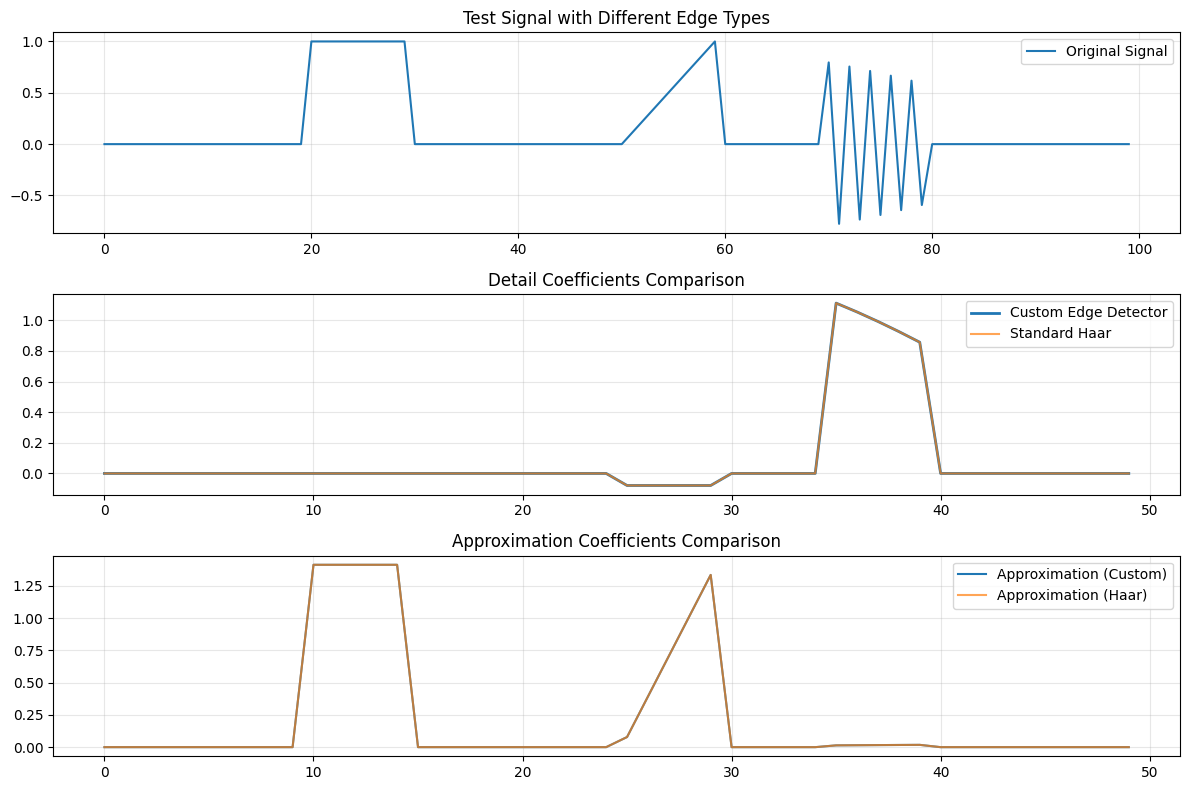

Edge Detection Performance:
Custom wavelet edge energy: 4.951
Standard Haar edge energy: 4.952
Improvement ratio: 1.000


In [ ]:
import pywt
import numpy as np
import matplotlib.pyplot as plt
from pywt import Wavelet

# Define custom wavelet optimized for edge detection
dec_lo = [0.7071, 0.7071]      # Normalized low-pass filter
dec_hi = [-0.7071, 0.7071]     # High-pass filter emphasizes differences
rec_lo = [0.7071, 0.7071]      # Reconstruction low-pass
rec_hi = [0.7071, -0.7071]     # Reconstruction high-pass

edge_wavelet = Wavelet(name="edge_detector", 
                      filter_bank=[dec_lo, dec_hi, rec_lo, rec_hi])

# Create test signal with multiple edge types
t = np.linspace(0, 10, 100)
signal = np.zeros_like(t)
signal[20:30] = 1      # Step edge
signal[50:60] = np.linspace(0, 1, 10)  # Ramp edge
signal[70:80] = np.sin(2*np.pi*t[70:80]*5)  # Oscillatory region

# Apply edge detection wavelet
coeffs = pywt.dwt(signal, edge_wavelet)
cA, cD = coeffs

# Compare with standard Haar wavelet
coeffs_haar = pywt.dwt(signal, 'haar')
cA_haar, cD_haar = coeffs_haar

# Visualization
plt.figure(figsize=(12, 8))

plt.subplot(3, 1, 1)
plt.plot(signal, label='Original Signal')
plt.title('Test Signal with Different Edge Types')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(3, 1, 2)
plt.plot(cD, label='Custom Edge Detector', linewidth=2)
plt.plot(cD_haar, label='Standard Haar', alpha=0.7)
plt.title('Detail Coefficients Comparison')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(3, 1, 3)
plt.plot(cA, label='Approximation (Custom)')
plt.plot(cA_haar, label='Approximation (Haar)', alpha=0.7)
plt.title('Approximation Coefficients Comparison')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('./output/custom_wavelets_edge_detection.png',dpi=300)
plt.show()

print("Edge Detection Performance:")
print(f"Custom wavelet edge energy: {np.sum(cD**2):.3f}")
print(f"Standard Haar edge energy: {np.sum(cD_haar**2):.3f}")
print(f"Improvement ratio: {np.sum(cD**2)/np.sum(cD_haar**2):.3f}")

### 5.6.2 Example 2: Biomedical Signal Processing

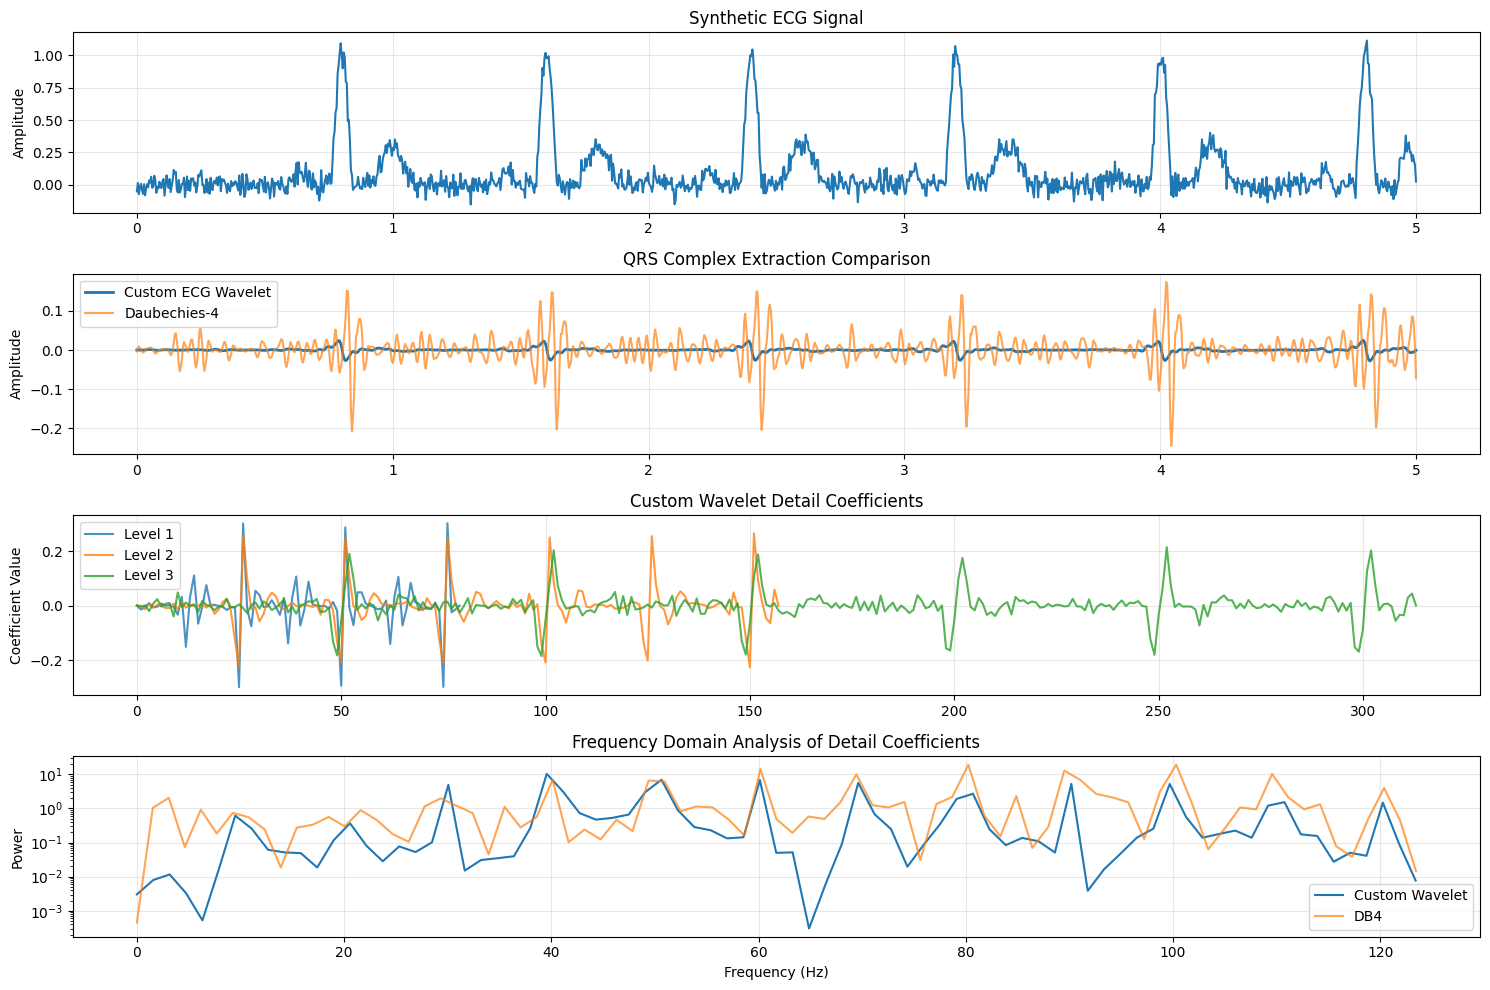

QRS detection performance:
Custom wavelet QRS energy: 0.893
DB4 wavelet QRS energy: 2.115
Energy concentration improvement: 0.422


In [ ]:
# Simulate ECG-like signal with P-QRS-T complexes
def generate_ecg_signal(duration=5, sampling_rate=250):
    """Generate synthetic ECG signal with realistic morphology."""
    t = np.linspace(0, duration, duration * sampling_rate)
    ecg = np.zeros_like(t)
    
    # Add multiple heartbeats
    for beat_time in np.arange(0.8, duration, 0.8):  # ~75 BPM
        beat_idx = int(beat_time * sampling_rate)
        
        # P wave
        p_indices = np.arange(beat_idx - 50, beat_idx - 30)
        p_indices = p_indices[(p_indices >= 0) & (p_indices < len(ecg))]
        ecg[p_indices] += 0.1 * np.sin(np.pi * np.arange(len(p_indices)) / len(p_indices))
        
        # QRS complex
        qrs_indices = np.arange(beat_idx - 10, beat_idx + 10)
        qrs_indices = qrs_indices[(qrs_indices >= 0) & (qrs_indices < len(ecg))]
        ecg[qrs_indices] += 1.0 * np.sin(np.pi * np.arange(len(qrs_indices)) / len(qrs_indices))
        
        # T wave
        t_indices = np.arange(beat_idx + 30, beat_idx + 70)
        t_indices = t_indices[(t_indices >= 0) & (t_indices < len(ecg))]
        ecg[t_indices] += 0.3 * np.sin(np.pi * np.arange(len(t_indices)) / len(t_indices))
    
    # Add noise
    ecg += 0.05 * np.random.randn(len(ecg))
    
    return t, ecg

# Generate test ECG signal
t, ecg_signal = generate_ecg_signal()

# Design custom wavelet for ECG processing
# Optimized for QRS complex detection and P/T wave preservation
dec_lo = [0.125, 0.375, 0.375, 0.125]    # Smoother low-pass
dec_hi = [-0.125, -0.375, 0.375, 0.125]  # Modified high-pass for QRS
rec_lo = [0.125, 0.375, 0.375, 0.125]
rec_hi = [0.125, -0.375, -0.375, 0.125]

ecg_wavelet = Wavelet(name="ecg_detector", 
                     filter_bank=[dec_lo, dec_hi, rec_lo, rec_hi])

# Multi-level decomposition for different frequency bands
levels = 4
coeffs_custom = pywt.wavedec(ecg_signal, ecg_wavelet, level=levels)
coeffs_db4 = pywt.wavedec(ecg_signal, 'db4', level=levels)

# Reconstruct different frequency bands
def reconstruct_band(coeffs, level_idx, wavelet):
    """Reconstruct signal from a specific decomposition level using the given wavelet."""
    coeffs_band = [np.zeros_like(c) if i != level_idx else c 
                   for i, c in enumerate(coeffs)]
    return pywt.waverec(coeffs_band, wavelet)

# Reconstruct QRS-dominant band
qrs_band_custom = reconstruct_band(coeffs_custom, 2, ecg_wavelet)
qrs_band_db4    = reconstruct_band(coeffs_db4, 2, 'db4')

# Frequency-domain analysis of the detail coefficients
def compute_power_spectrum(coeff):
    freqs = np.fft.fftfreq(len(coeff), 1/250)
    power = np.abs(np.fft.fft(coeff))**2
    return freqs[:len(freqs)//2], power[:len(power)//2]

freqs_custom, power_custom = compute_power_spectrum(coeffs_custom[2])
freqs_db4,    power_db4    = compute_power_spectrum(coeffs_db4[2])

# Visualization
plt.figure(figsize=(15, 10))

plt.subplot(4, 1, 1)
plt.plot(t, ecg_signal)
plt.title('Synthetic ECG Signal')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)

plt.subplot(4, 1, 2)
plt.plot(t, qrs_band_custom, label='Custom ECG Wavelet', linewidth=2)
plt.plot(t, qrs_band_db4, label='Daubechies-4', alpha=0.7)
plt.title('QRS Complex Extraction Comparison')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(4, 1, 3)
for i, coeff in enumerate(coeffs_custom[1:4]):  # Detail levels 1-3
    plt.plot(coeff, label=f'Level {i+1}', alpha=0.8)
plt.title('Custom Wavelet Detail Coefficients')
plt.ylabel('Coefficient Value')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(4, 1, 4)
plt.semilogy(freqs_custom, power_custom, label='Custom Wavelet')
plt.semilogy(freqs_db4, power_db4, label='DB4', alpha=0.7)
plt.title('Frequency Domain Analysis of Detail Coefficients')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('./output/custom_wavelets_qrs_detection.png',dpi=300)
plt.show()

# Performance metrics
qrs_energy_custom = np.sum(coeffs_custom[2]**2)
qrs_energy_db4 = np.sum(coeffs_db4[2]**2)

print(f"QRS detection performance:")
print(f"Custom wavelet QRS energy: {qrs_energy_custom:.3f}")
print(f"DB4 wavelet QRS energy: {qrs_energy_db4:.3f}")
print(f"Energy concentration improvement: {qrs_energy_custom/qrs_energy_db4:.3f}")


### 5.6.3 Example 3: Multi-Level Decomposition with Performance Analysis

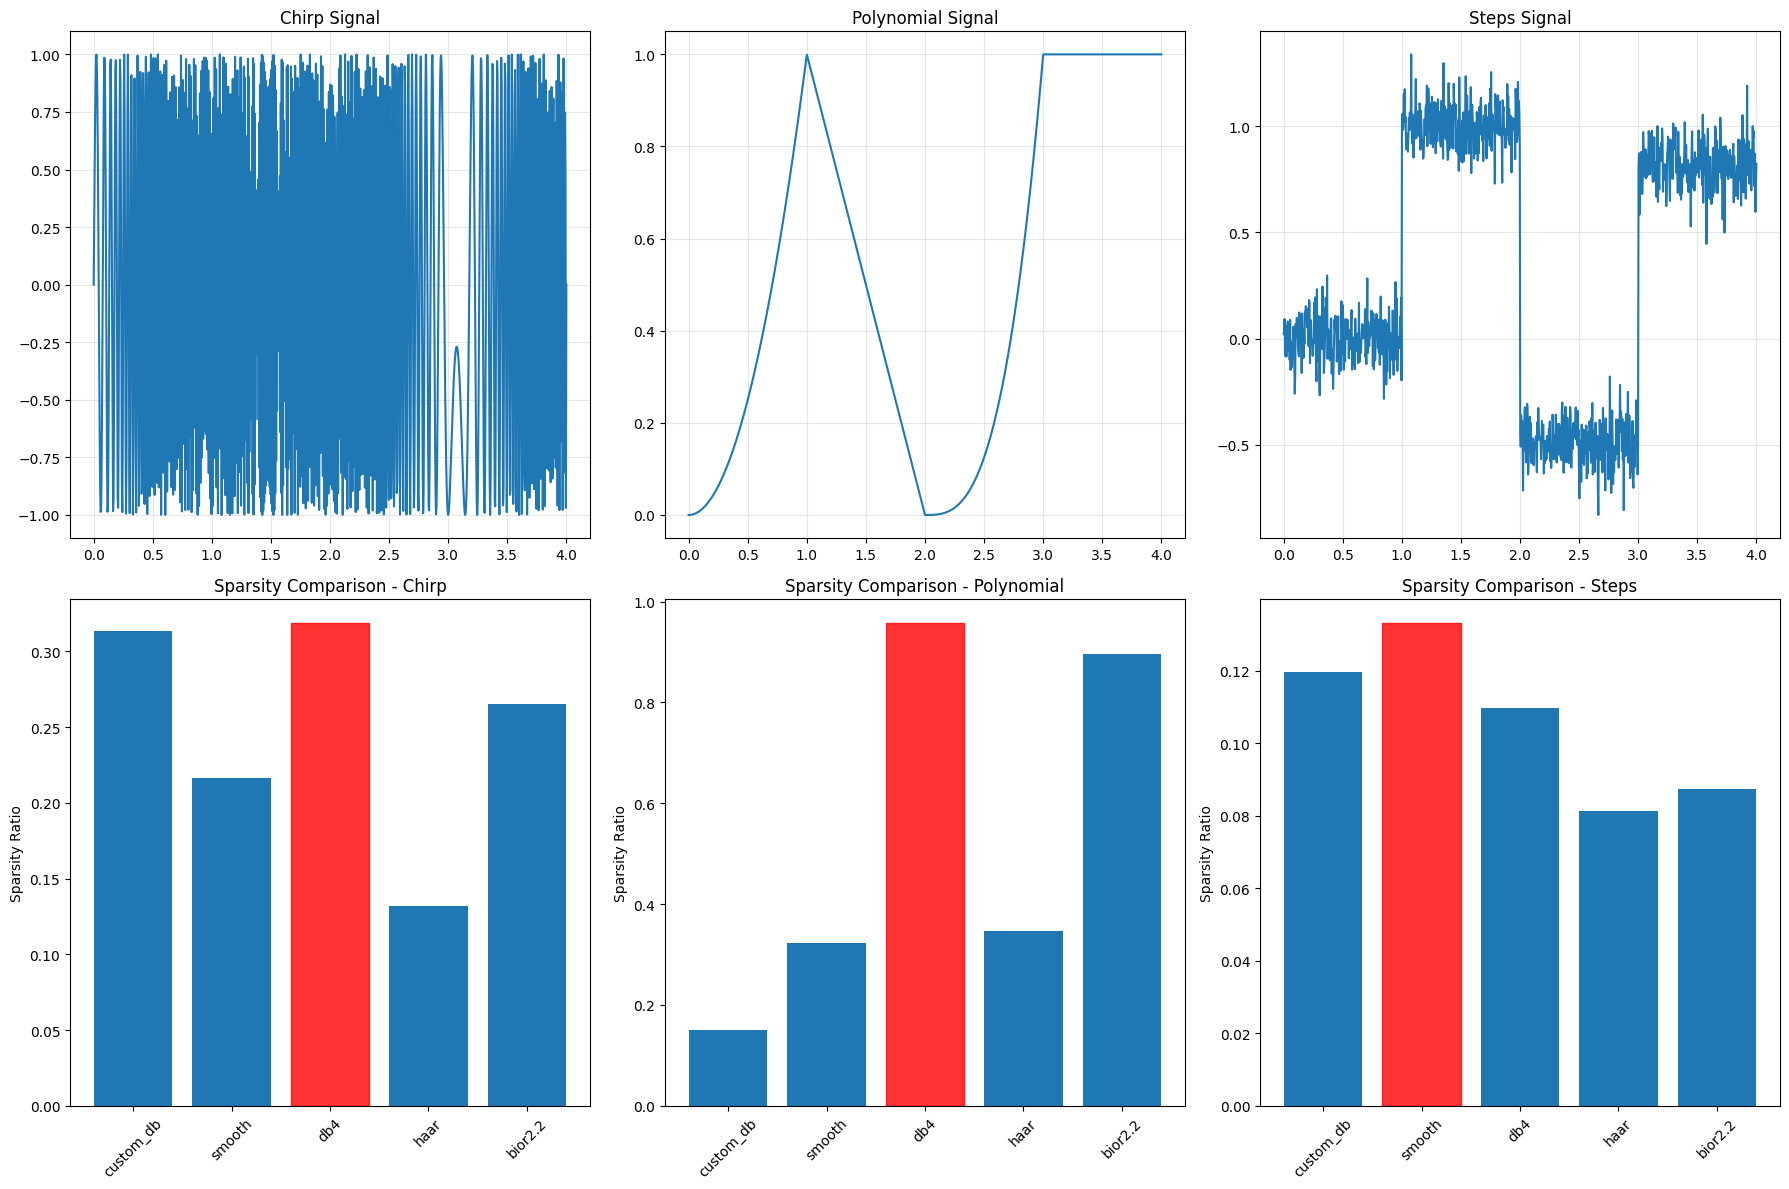

Performance Summary:

CHIRP SIGNAL:
------------------------------
custom_db      : Sparsity=0.313, Error=5.73e-04
smooth         : Sparsity=0.216, Error=3.42e-01
db4            : Sparsity=0.319, Error=2.84e-32
haar           : Sparsity=0.132, Error=4.78e-32
bior2.2        : Sparsity=0.265, Error=1.81e-32

POLYNOMIAL SIGNAL:
------------------------------
custom_db      : Sparsity=0.149, Error=4.41e-03
smooth         : Sparsity=0.322, Error=3.21e-01
db4            : Sparsity=0.957, Error=2.25e-32
haar           : Sparsity=0.347, Error=4.33e-32
bior2.2        : Sparsity=0.895, Error=1.77e-32

STEPS SIGNAL:
------------------------------
custom_db      : Sparsity=0.120, Error=4.97e-03
smooth         : Sparsity=0.133, Error=3.73e-01
db4            : Sparsity=0.110, Error=4.13e-32
haar           : Sparsity=0.081, Error=9.60e-32
bior2.2        : Sparsity=0.087, Error=1.92e-32


In [ ]:
# Create more sophisticated test signals
def create_test_signals():
    """Create diverse test signals for comprehensive evaluation."""
    t = np.linspace(0, 4, 1024)
    
    signals = {}
    
    # Chirp signal (frequency sweep)
    signals['chirp'] = np.sin(2 * np.pi * (10 + 40 * t) * t)
    
    # Piecewise polynomial
    signals['polynomial'] = np.piecewise(t, 
                                       [t < 1, (t >= 1) & (t < 2), 
                                        (t >= 2) & (t < 3), t >= 3],
                                       [lambda x: x**2, lambda x: 2-x, 
                                        lambda x: (x-2)**3, lambda x: 1])
    
    # Noisy step function
    signals['steps'] = np.piecewise(t, [t < 1, (t >= 1) & (t < 2), 
                                       (t >= 2) & (t < 3), t >= 3],
                                   [0, 1, -0.5, 0.8])
    signals['steps'] += 0.1 * np.random.randn(len(t))
    
    return t, signals

t, test_signals = create_test_signals()

# Define multiple custom wavelets for comparison
wavelets = {}

# Daubechies-like custom wavelet
daubechies_custom = [-0.01059740178507, 0.03288301166689, 0.03084138183556,
                    -0.18703481171909, -0.02798376941686, 0.63088076792959,
                     0.71484657055292, 0.20484142886663]
wavelets['custom_db'] = Wavelet(name="custom_db", 
                               filter_bank=[daubechies_custom,
                                          [-x * (-1)**i for i, x in enumerate(daubechies_custom[::-1])],
                                          daubechies_custom[::-1],
                                          [x * (-1)**i for i, x in enumerate(daubechies_custom)]])

# Smooth custom wavelet for polynomial signals
smooth_lo = [0.125, 0.375, 0.375, 0.125]
smooth_hi = [-0.125, -0.375, 0.375, 0.125]
wavelets['smooth'] = Wavelet(name="smooth", 
                            filter_bank=[smooth_lo, smooth_hi, smooth_lo, smooth_hi[::-1]])

# Performance evaluation function
def evaluate_wavelet_performance(signal, wavelet, levels=3):
    """Evaluate wavelet performance on a given signal."""
    coeffs = pywt.wavedec(signal, wavelet, level=levels)
    
    # Energy distribution across levels
    energies = [np.sum(c**2) for c in coeffs]
    total_energy = sum(energies)
    energy_ratios = [e/total_energy for e in energies]
    
    # Sparsity measure (percentage of coefficients below threshold)
    all_coeffs = np.concatenate(coeffs[1:])  # Detail coefficients only
    threshold = 0.1 * np.std(all_coeffs)
    sparsity = np.sum(np.abs(all_coeffs) < threshold) / len(all_coeffs)
    
    # Reconstruction error
    reconstructed = pywt.waverec(coeffs, wavelet)
    if len(reconstructed) != len(signal):
        min_len = min(len(reconstructed), len(signal))
        reconstruction_error = np.mean((signal[:min_len] - reconstructed[:min_len])**2)
    else:
        reconstruction_error = np.mean((signal - reconstructed)**2)
    
    return {
        'energy_distribution': energy_ratios,
        'sparsity': sparsity,
        'reconstruction_error': reconstruction_error,
        'coefficients': coeffs
    }

# Comprehensive performance analysis
results = {}
for signal_name, signal in test_signals.items():
    results[signal_name] = {}
    
    # Test custom wavelets and standard wavelets
    test_wavelets = {**wavelets, 'db4': 'db4', 'haar': 'haar', 'bior2.2': 'bior2.2'}
    
    for wavelet_name, wavelet in test_wavelets.items():
        results[signal_name][wavelet_name] = evaluate_wavelet_performance(signal, wavelet)

# Visualization of results
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
signal_names = list(test_signals.keys())

for i, signal_name in enumerate(signal_names):
    # Plot original signals
    axes[0, i].plot(t, test_signals[signal_name])
    axes[0, i].set_title(f'{signal_name.capitalize()} Signal')
    axes[0, i].grid(True, alpha=0.3)
    
    # Plot sparsity comparison
    wavelet_names = list(results[signal_name].keys())
    sparsity_values = [results[signal_name][w]['sparsity'] for w in wavelet_names]
    
    bars = axes[1, i].bar(wavelet_names, sparsity_values)
    axes[1, i].set_title(f'Sparsity Comparison - {signal_name.capitalize()}')
    axes[1, i].set_ylabel('Sparsity Ratio')
    axes[1, i].tick_params(axis='x', rotation=45)
    
    # Highlight best performing wavelets
    best_idx = np.argmax(sparsity_values)
    bars[best_idx].set_color('red')
    bars[best_idx].set_alpha(0.8)

plt.tight_layout()
plt.savefig('./output/custom_wavelets_performance_analysis.png',dpi=300)
plt.show()

# Performance summary table
print("Performance Summary:")
print("="*60)
for signal_name in signal_names:
    print(f"\n{signal_name.upper()} SIGNAL:")
    print("-" * 30)
    for wavelet_name in results[signal_name].keys():
        result = results[signal_name][wavelet_name]
        print(f"{wavelet_name:15s}: Sparsity={result['sparsity']:.3f}, "
              f"Error={result['reconstruction_error']:.2e}")

### 5.6.4 Example 4: Adaptive Wavelet Design for Time Series

Generating training data...
Designing adaptive wavelets...
Optimizing for sparsity...
✓ Successfully created adaptive wavelet for sparsity
Optimizing for energy_concentration...
✓ Successfully created adaptive wavelet for energy_concentration
Optimizing for denoising...
✓ Successfully created adaptive wavelet for denoising

Analyzing wavelet performance...


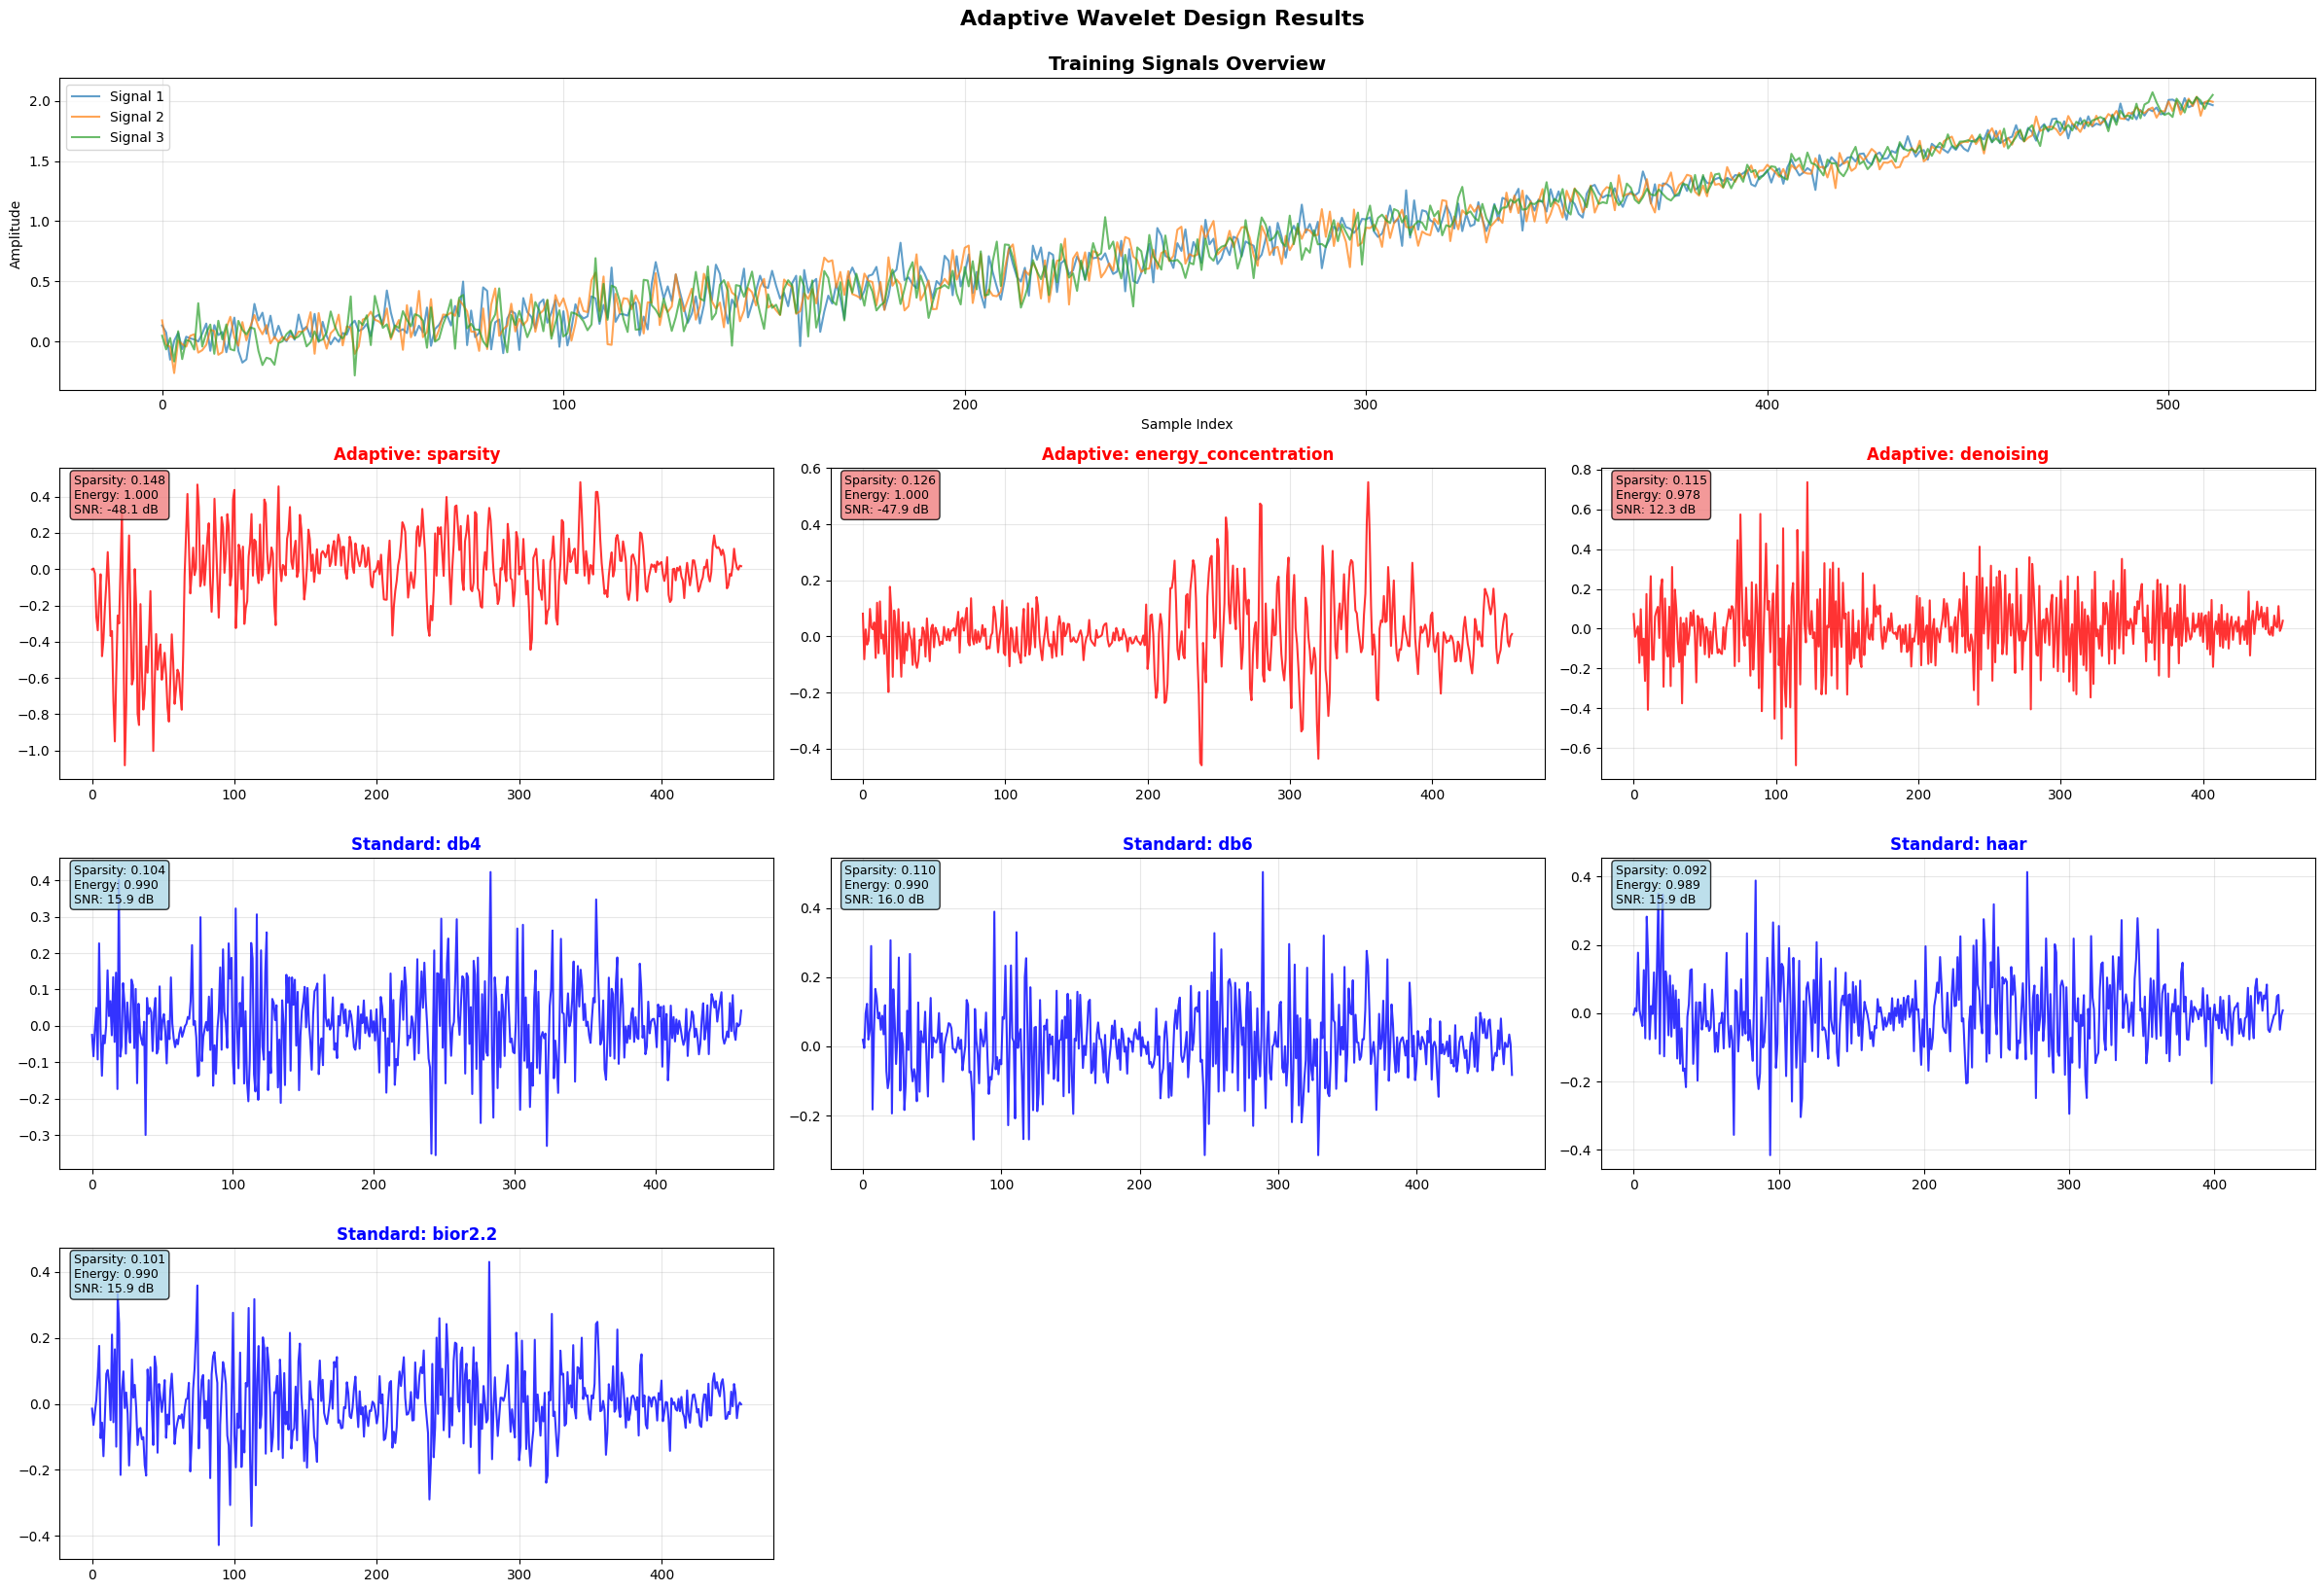

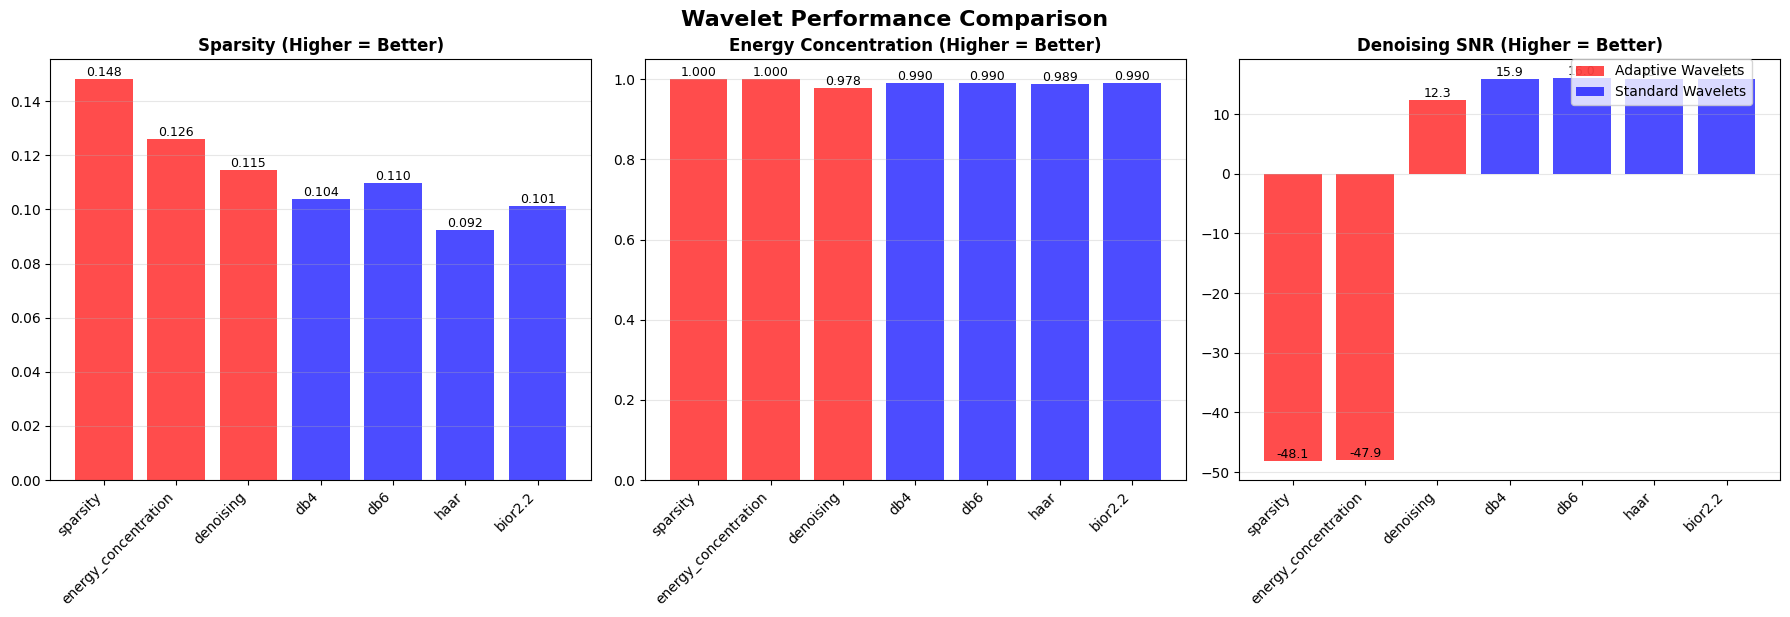


Performance Summary:
Wavelet              Sparsity   Energy Conc. Denoising SNR  
----------------------------------------------------------------------
sparsity             0.148      1.000        -48.1          
energy_concentration 0.126      1.000        -47.9          
denoising            0.115      0.978        12.3           
db4                  0.104      0.990        15.9           
db6                  0.110      0.990        16.0           
haar                 0.092      0.989        15.9           
bior2.2              0.101      0.990        15.9           

✓ Created 3 adaptive wavelets
✓ Compared against 4 standard wavelets


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pywt
from scipy.optimize import differential_evolution
from pywt import Wavelet
import warnings
warnings.filterwarnings('ignore')

def design_adaptive_wavelet(training_signals, target_property='sparsity', filter_length=6):
    """
    Design an adaptive wavelet optimized for specific signal characteristics.
    
    Parameters:
    -----------
    training_signals : list of arrays
        Training signals for optimization
    target_property : str
        Optimization target ('sparsity', 'energy_concentration', 'denoising')
    filter_length : int
        Length of the wavelet filters (must be even)
    
    Returns:
    --------
    Wavelet : Optimized adaptive wavelet
    """
    
    def enforce_orthogonality_conditions(h0):
        """Enforce basic orthogonality conditions for wavelet filters."""
        # Normalize for unit norm
        h0 = h0 / np.sqrt(np.sum(h0**2)) * np.sqrt(2)
        
        # Create high-pass filter using quadrature mirror relationship
        h1 = np.zeros_like(h0)
        for k in range(len(h0)):
            h1[k] = (-1)**k * h0[len(h0) - 1 - k]
        
        return h0, h1
    
    def create_reconstruction_filters(h0, h1):
        """Create reconstruction filters from decomposition filters."""
        # For orthogonal wavelets: g0 = h0[::-1], g1 = h1[::-1]
        g0 = h0[::-1]
        g1 = h1[::-1]
        return g0, g1
    
    def objective_function(coeffs):
        """Objective function for wavelet optimization."""
        try:
            # Extract low-pass decomposition filter
            h0 = coeffs[:filter_length]
            
            # Enforce orthogonality and create filter bank
            h0, h1 = enforce_orthogonality_conditions(h0)
            g0, g1 = create_reconstruction_filters(h0, h1)
            
            # Create temporary wavelet
            try:
                temp_wavelet = Wavelet(name="temp_adaptive",
                                     filter_bank=[h0, h1, g0, g1])
            except:
                return float('inf')
            
            total_score = 0
            valid_signals = 0
            
            for signal in training_signals:
                try:
                    # Ensure signal length is appropriate for decomposition
                    min_len = 2 ** 4  # Minimum length for 3-level decomposition
                    if len(signal) < min_len:
                        continue
                    
                    coeffs_decomp = pywt.wavedec(signal, temp_wavelet, level=3)
                    
                    if target_property == 'sparsity':
                        # Maximize sparsity in detail coefficients
                        detail_coeffs = np.concatenate(coeffs_decomp[1:])
                        if len(detail_coeffs) == 0:
                            continue
                        threshold = 0.1 * np.std(detail_coeffs)
                        sparsity = np.sum(np.abs(detail_coeffs) < threshold) / len(detail_coeffs)
                        total_score += sparsity
                        
                    elif target_property == 'energy_concentration':
                        # Maximize energy concentration in approximation
                        total_energy = sum(np.sum(c**2) for c in coeffs_decomp)
                        if total_energy == 0:
                            continue
                        approx_energy = np.sum(coeffs_decomp[0]**2)
                        concentration = approx_energy / total_energy
                        total_score += concentration
                        
                    elif target_property == 'denoising':
                        # Optimize for denoising performance with more stable approach
                        np.random.seed(42)  # Fixed seed for reproducibility
                        noise_level = 0.1 * np.std(signal)
                        noisy_signal = signal + noise_level * np.random.randn(len(signal))
                        
                        try:
                            noisy_coeffs = pywt.wavedec(noisy_signal, temp_wavelet, level=3)
                            
                            # Soft thresholding with adaptive threshold
                            sigma = noise_level
                            threshold = sigma * np.sqrt(2 * np.log(len(signal)))
                            
                            denoised_coeffs = [noisy_coeffs[0]]  # Keep approximation
                            for c in noisy_coeffs[1:]:
                                denoised_coeffs.append(
                                    np.sign(c) * np.maximum(np.abs(c) - threshold, 0)
                                )
                            
                            denoised_signal = pywt.waverec(denoised_coeffs, temp_wavelet)
                            
                            # Handle length mismatch
                            min_len = min(len(denoised_signal), len(signal))
                            mse = np.mean((signal[:min_len] - denoised_signal[:min_len])**2)
                            
                            if np.isfinite(mse) and mse > 0:
                                # Use SNR improvement as score
                                noise_power = np.var(signal - noisy_signal[:len(signal)])
                                if noise_power > 0:
                                    snr_improvement = 10 * np.log10(noise_power / (mse + 1e-10))
                                    total_score += snr_improvement
                                else:
                                    total_score += -mse
                        except:
                            continue
                    
                    valid_signals += 1
                    
                except Exception:
                    continue
            
            if valid_signals == 0:
                return float('inf')
            
            avg_score = total_score / valid_signals
            return -avg_score  # Minimize negative score
            
        except Exception:
            return float('inf')
    
    # Optimization with better bounds and constraints
    bounds = [(-1, 1) for _ in range(filter_length)]
    
    # Multiple optimization runs with different seeds for robustness
    best_result = None
    best_score = float('inf')
    
    for seed in [42, 123, 456, 789]:
        try:
            result = differential_evolution(
                objective_function, 
                bounds, 
                seed=seed, 
                maxiter=200,
                popsize=15,
                atol=1e-6,
                tol=1e-4
            )
            
            if result.fun < best_score:
                best_score = result.fun
                best_result = result
                
        except Exception:
            continue
    
    if best_result is not None and best_result.fun < float('inf'):
        coeffs = best_result.x
        
        # Construct final wavelet
        h0 = coeffs[:filter_length]
        h0, h1 = enforce_orthogonality_conditions(h0)
        g0, g1 = create_reconstruction_filters(h0, h1)
        
        try:
            return Wavelet(name=f"adaptive_{target_property}",
                          filter_bank=[h0, h1, g0, g1])
        except:
            raise ValueError(f"Failed to create valid wavelet for {target_property}")
    else:
        raise ValueError(f"Adaptive wavelet optimization failed for {target_property}")

def generate_training_data():
    """Generate diverse training signals for adaptive wavelet design."""
    signals = []
    
    # Financial time series like signals
    for i in range(5):
        np.random.seed(i + 10)
        t = np.linspace(0, 10, 512)  # Increased length
        trend = 0.1 * t + 0.01 * t**2
        volatility = 0.1 + 0.05 * np.sin(0.5 * t)
        noise = np.random.randn(len(t))
        signal = trend + volatility * noise
        signals.append(signal)
    
    # Biomedical-like signals
    for i in range(5):
        np.random.seed(i + 20)
        t = np.linspace(0, 10, 512)
        periodic = np.sin(2 * np.pi * 1.2 * t) + 0.3 * np.sin(2 * np.pi * 3.5 * t)
        artifacts = np.zeros_like(t)
        # Add random spikes
        spike_indices = np.random.choice(len(t), size=5, replace=False)
        artifacts[spike_indices] = np.random.randn(len(spike_indices)) * 3
        signal = periodic + 0.2 * np.random.randn(len(t)) + artifacts
        signals.append(signal)
    
    # Piecewise smooth signals
    for i in range(3):
        np.random.seed(i + 30)
        t = np.linspace(0, 10, 512)
        signal = np.piecewise(t, 
                             [t < 2, (t >= 2) & (t < 5), (t >= 5) & (t < 8), t >= 8],
                             [lambda x: np.sin(x), 
                              lambda x: 2 * np.cos(2*x), 
                              lambda x: 0.5 * x,
                              lambda x: np.exp(-0.5*(x-8))])
        signal += 0.1 * np.random.randn(len(signal))
        signals.append(signal)
    
    return signals

def analyze_wavelet_performance(wavelets_dict, test_signals):
    """Analyze performance of different wavelets on test signals."""
    results = {}
    
    for wavelet_name, wavelet in wavelets_dict.items():
        scores = {'sparsity': [], 'energy_conc': [], 'denoising': []}
        
        for signal in test_signals:
            try:
                coeffs = pywt.wavedec(signal, wavelet, level=3)
                
                # Sparsity measure
                detail_coeffs = np.concatenate(coeffs[1:])
                if len(detail_coeffs) > 0:
                    threshold = 0.1 * np.std(detail_coeffs)
                    sparsity = np.sum(np.abs(detail_coeffs) < threshold) / len(detail_coeffs)
                    scores['sparsity'].append(sparsity)
                
                # Energy concentration
                total_energy = sum(np.sum(c**2) for c in coeffs)
                if total_energy > 0:
                    approx_energy = np.sum(coeffs[0]**2)
                    concentration = approx_energy / total_energy
                    scores['energy_conc'].append(concentration)
                
                # Denoising performance
                noise_level = 0.1 * np.std(signal)
                noisy_signal = signal + noise_level * np.random.randn(len(signal))
                noisy_coeffs = pywt.wavedec(noisy_signal, wavelet, level=3)
                
                # Soft thresholding
                threshold = noise_level * np.sqrt(2 * np.log(len(signal)))
                denoised_coeffs = [noisy_coeffs[0]]
                for c in noisy_coeffs[1:]:
                    denoised_coeffs.append(np.sign(c) * np.maximum(np.abs(c) - threshold, 0))
                
                denoised_signal = pywt.waverec(denoised_coeffs, wavelet)
                min_len = min(len(denoised_signal), len(signal))
                mse = np.mean((signal[:min_len] - denoised_signal[:min_len])**2)
                
                if np.isfinite(mse) and mse > 0:
                    snr = 10 * np.log10(np.var(signal) / mse)
                    scores['denoising'].append(snr)
                    
            except Exception:
                continue
        
        # Average scores
        results[wavelet_name] = {
            'sparsity': np.mean(scores['sparsity']) if scores['sparsity'] else 0,
            'energy_conc': np.mean(scores['energy_conc']) if scores['energy_conc'] else 0,
            'denoising_snr': np.mean(scores['denoising']) if scores['denoising'] else 0
        }
    
    return results

# Main execution
if __name__ == "__main__":
    print("Generating training data...")
    training_data = generate_training_data()
    
    print("Designing adaptive wavelets...")
    adaptive_wavelets = {}
    
    targets = ['sparsity', 'energy_concentration', 'denoising']
    
    for target in targets:
        print(f"Optimizing for {target}...")
        try:
            adaptive_wavelets[target] = design_adaptive_wavelet(
                training_data, target, filter_length=6
            )
            print(f"✓ Successfully created adaptive wavelet for {target}")
        except Exception as e:
            print(f"✗ Failed to create adaptive wavelet for {target}: {e}")
    
    # Add standard wavelets for comparison
    standard_wavelets = {
        'db4': 'db4',
        'db6': 'db6', 
        'haar': 'haar',
        'bior2.2': 'bior2.2'
    }
    
    all_wavelets = {**adaptive_wavelets, **standard_wavelets}
    
    # Analyze performance
    print("\nAnalyzing wavelet performance...")
    test_signals = training_data[:3]  # Use subset for testing
    performance = analyze_wavelet_performance(all_wavelets, test_signals)
    
    # Create comprehensive visualization with better layout
    fig = plt.figure(figsize=(24, 16))
    
    # First figure: Training signals
    plt.subplot(4, 1, 1)
    for i, signal in enumerate(training_data[:3]):
        plt.plot(signal, alpha=0.7, label=f'Signal {i+1}')
    plt.title('Training Signals Overview', fontsize=14, fontweight='bold')
    plt.xlabel('Sample Index')
    plt.ylabel('Amplitude')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Second section: Adaptive wavelets performance
    adaptive_names = [name for name in all_wavelets.keys() if name in adaptive_wavelets]
    standard_names = [name for name in all_wavelets.keys() if name not in adaptive_wavelets]
    
    test_signal = training_data[0]
    
    # Plot adaptive wavelets
    n_adaptive = len(adaptive_names)
    if n_adaptive > 0:
        for i, name in enumerate(adaptive_names):
            plt.subplot(4, max(3, n_adaptive), n_adaptive + 1 + i)
            
            try:
                wavelet = all_wavelets[name]
                coeffs = pywt.wavedec(test_signal, wavelet, level=3)
                detail_coeffs = np.concatenate(coeffs[1:])
                
                plt.plot(detail_coeffs, alpha=0.8, color='red', linewidth=1.5)
                plt.title(f'Adaptive: {name}', fontsize=12, fontweight='bold', color='red')
                plt.grid(True, alpha=0.3)
                
                if name in performance:
                    perf = performance[name]
                    plt.text(0.02, 0.98, 
                            f'Sparsity: {perf["sparsity"]:.3f}\nEnergy: {perf["energy_conc"]:.3f}\nSNR: {perf["denoising_snr"]:.1f} dB',
                            transform=plt.gca().transAxes, verticalalignment='top',
                            fontsize=9, bbox=dict(boxstyle='round,pad=0.3', facecolor='lightcoral', alpha=0.8))
                
            except Exception as e:
                plt.text(0.5, 0.5, f'Failed to create\n{name}\nError: {str(e)[:40]}...', 
                        ha='center', va='center', transform=plt.gca().transAxes,
                        fontsize=10, bbox=dict(boxstyle='round', facecolor='lightgray'))
                plt.title(f'Adaptive: {name} (Failed)', fontsize=12, color='red')
    
    # Plot standard wavelets for comparison
    n_standard = min(6, len(standard_names))  # Limit to 6 for layout
    for i, name in enumerate(standard_names[:n_standard]):
        row = 2 + i // 3
        col = i % 3
        plt.subplot(4, 3, row * 3 + col + 1)
        
        try:
            wavelet = all_wavelets[name]
            coeffs = pywt.wavedec(test_signal, wavelet, level=3)
            detail_coeffs = np.concatenate(coeffs[1:])
            
            plt.plot(detail_coeffs, alpha=0.8, color='blue', linewidth=1.5)
            plt.title(f'Standard: {name}', fontsize=12, fontweight='bold', color='blue')
            plt.grid(True, alpha=0.3)
            
            if name in performance:
                perf = performance[name]
                plt.text(0.02, 0.98, 
                        f'Sparsity: {perf["sparsity"]:.3f}\nEnergy: {perf["energy_conc"]:.3f}\nSNR: {perf["denoising_snr"]:.1f} dB',
                        transform=plt.gca().transAxes, verticalalignment='top',
                        fontsize=9, bbox=dict(boxstyle='round,pad=0.3', facecolor='lightblue', alpha=0.8))
            
        except Exception as e:
            plt.text(0.5, 0.5, f'Error with {name}:\n{str(e)[:40]}...', 
                    ha='center', va='center', transform=plt.gca().transAxes,
                    fontsize=10)
            plt.title(f'Standard: {name} (Error)', fontsize=12, color='blue')
    
    plt.tight_layout()
    plt.suptitle('Adaptive Wavelet Design Results', fontsize=16, fontweight='bold', y=1.02)
    plt.savefig('./output/adaptive_wavelet_design.png',dpi=300)
    plt.show()
    
    # Create a separate performance comparison plot
    if performance:
        fig, axes = plt.subplots(1, 3, figsize=(18, 6))
        
        metrics = ['sparsity', 'energy_conc', 'denoising_snr']
        titles = ['Sparsity (Higher = Better)', 'Energy Concentration (Higher = Better)', 'Denoising SNR (Higher = Better)']
        
        for i, (metric, title) in enumerate(zip(metrics, titles)):
            names = list(performance.keys())
            values = [performance[name][metric] for name in names]
            
            # Color code: red for adaptive, blue for standard
            colors = ['red' if name in adaptive_wavelets else 'blue' for name in names]
            
            bars = axes[i].bar(range(len(names)), values, color=colors, alpha=0.7)
            axes[i].set_title(title, fontsize=12, fontweight='bold')
            axes[i].set_xticks(range(len(names)))
            axes[i].set_xticklabels(names, rotation=45, ha='right')
            axes[i].grid(True, alpha=0.3, axis='y')
            
            # Add value labels on bars
            for bar, value in zip(bars, values):
                height = bar.get_height()
                axes[i].text(bar.get_x() + bar.get_width()/2., height,
                           f'{value:.3f}' if metric != 'denoising_snr' else f'{value:.1f}',
                           ha='center', va='bottom', fontsize=9)
        
        # Add legend
        from matplotlib.patches import Patch
        legend_elements = [Patch(facecolor='red', alpha=0.7, label='Adaptive Wavelets'),
                          Patch(facecolor='blue', alpha=0.7, label='Standard Wavelets')]
        fig.legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(0.98, 0.95))
        
        plt.tight_layout()
        plt.suptitle('Wavelet Performance Comparison', fontsize=16, fontweight='bold', y=1.02)
        plt.savefig('./output/wavelet_performance_comparison.png',dpi=300)
        plt.show()
    
    # Print performance summary
    print("\nPerformance Summary:")
    print("="*70)
    print(f"{'Wavelet':<20} {'Sparsity':<10} {'Energy Conc.':<12} {'Denoising SNR':<15}")
    print("-"*70)
    
    for name, perf in performance.items():
        print(f"{name:<20} {perf['sparsity']:<10.3f} {perf['energy_conc']:<12.3f} {perf['denoising_snr']:<15.1f}")
    
    print(f"\n✓ Created {len(adaptive_wavelets)} adaptive wavelets")
    print(f"✓ Compared against {len(standard_wavelets)} standard wavelets")

## 5.7 Visualization of Custom Wavelets

### 5.7.1 Basic Wavelet Function Visualization

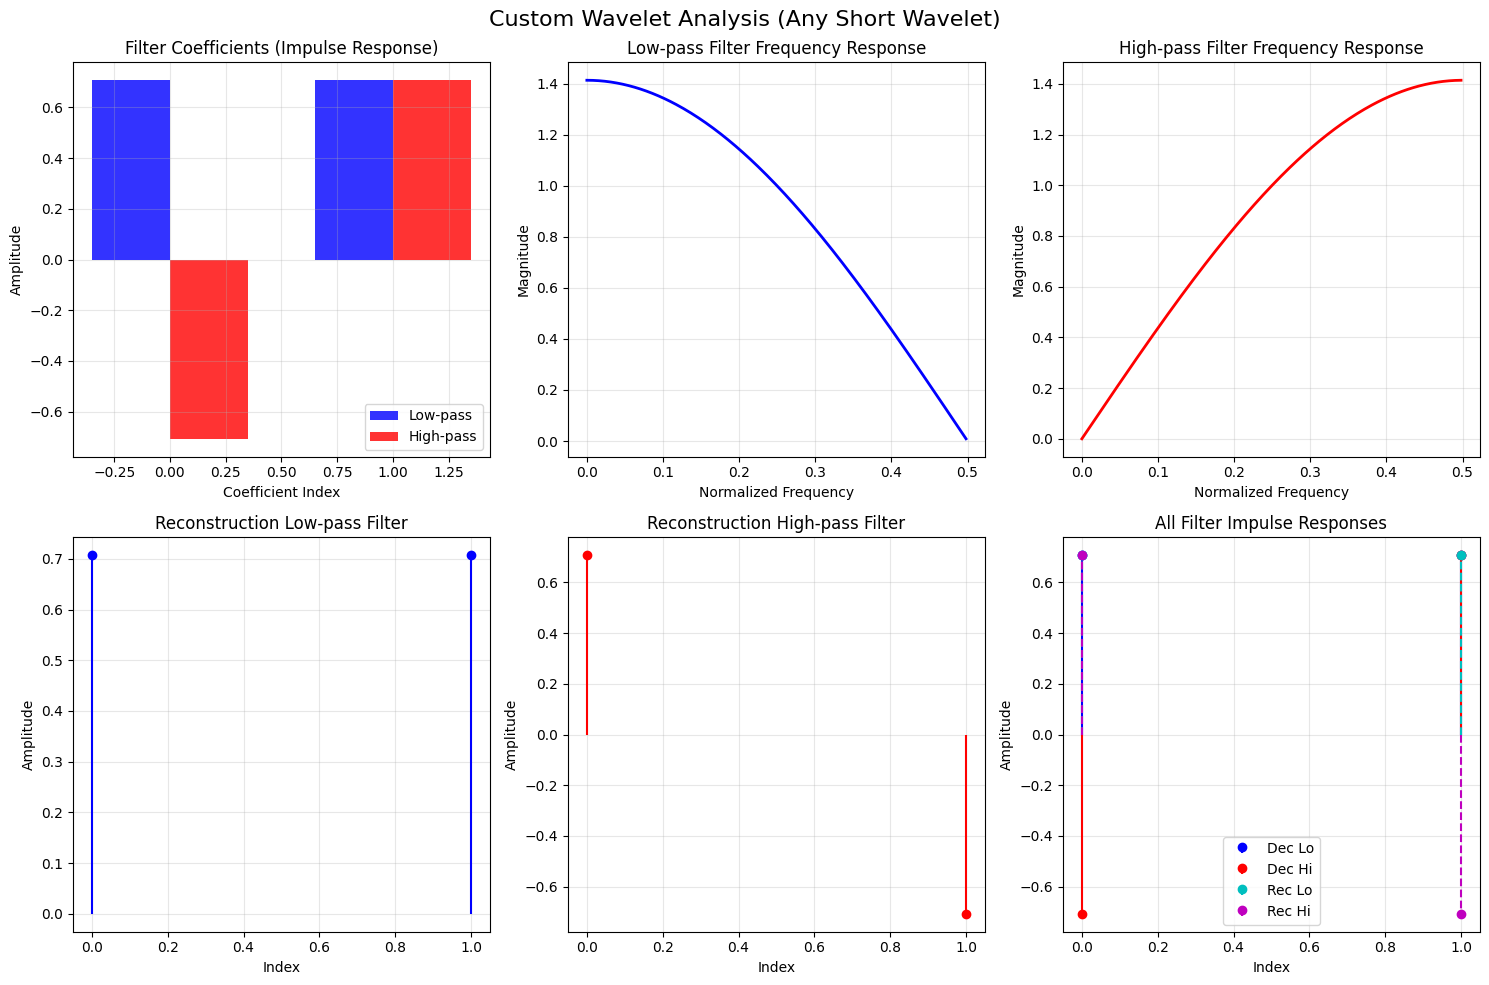

In [ ]:
import pywt
import matplotlib.pyplot as plt
import numpy as np

# Define custom wavelet filter coefficients
dec_lo = [0.7071, 0.7071]      # Low-pass decomposition
dec_hi = [-0.7071, 0.7071]     # High-pass decomposition
rec_lo = [0.7071, 0.7071]      # Low-pass reconstruction
rec_hi = [0.7071, -0.7071]     # High-pass reconstruction

# Create custom wavelet
custom_wavelet = pywt.Wavelet(
    name="visualized_wavelet",
    filter_bank=[dec_lo, dec_hi, rec_lo, rec_hi]
)

# -----------------------------
# Visualization for short custom wavelets
# -----------------------------
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# 1. Impulse response of scaling (low-pass) and wavelet (high-pass) filters
filter_indices = np.arange(len(dec_lo))
width = 0.35
axes[0, 0].bar(filter_indices - width/2, dec_lo, width, label='Low-pass', color='blue', alpha=0.8)
axes[0, 0].bar(filter_indices + width/2, dec_hi, width, label='High-pass', color='red', alpha=0.8)
axes[0, 0].set_title('Filter Coefficients (Impulse Response)')
axes[0, 0].set_xlabel('Coefficient Index')
axes[0, 0].set_ylabel('Amplitude')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# 2. Frequency response of low-pass filter
freq_lo = np.fft.fftfreq(512, d=1)
freq_resp_lo = np.abs(np.fft.fft(dec_lo, n=512))
axes[0, 1].plot(freq_lo[:256], freq_resp_lo[:256], 'b-', linewidth=2)
axes[0, 1].set_title('Low-pass Filter Frequency Response')
axes[0, 1].set_xlabel('Normalized Frequency')
axes[0, 1].set_ylabel('Magnitude')
axes[0, 1].grid(True, alpha=0.3)

# 3. Frequency response of high-pass filter
freq_hi = np.fft.fftfreq(512, d=1)
freq_resp_hi = np.abs(np.fft.fft(dec_hi, n=512))
axes[0, 2].plot(freq_hi[:256], freq_resp_hi[:256], 'r-', linewidth=2)
axes[0, 2].set_title('High-pass Filter Frequency Response')
axes[0, 2].set_xlabel('Normalized Frequency')
axes[0, 2].set_ylabel('Magnitude')
axes[0, 2].grid(True, alpha=0.3)

# 4. Reconstruction impulse response (low-pass)
axes[1, 0].stem(rec_lo, linefmt='b-', markerfmt='bo', basefmt=' ')
axes[1, 0].set_title('Reconstruction Low-pass Filter')
axes[1, 0].set_xlabel('Index')
axes[1, 0].set_ylabel('Amplitude')
axes[1, 0].grid(True, alpha=0.3)

# 5. Reconstruction impulse response (high-pass)
axes[1, 1].stem(rec_hi, linefmt='r-', markerfmt='ro', basefmt=' ')
axes[1, 1].set_title('Reconstruction High-pass Filter')
axes[1, 1].set_xlabel('Index')
axes[1, 1].set_ylabel('Amplitude')
axes[1, 1].grid(True, alpha=0.3)

# 6. Combined filters (for overview)
axes[1, 2].stem(dec_lo, linefmt='b-', markerfmt='bo', basefmt=' ', label='Dec Lo')
axes[1, 2].stem(dec_hi, linefmt='r-', markerfmt='ro', basefmt=' ', label='Dec Hi')
axes[1, 2].stem(rec_lo, linefmt='c--', markerfmt='co', basefmt=' ', label='Rec Lo')
axes[1, 2].stem(rec_hi, linefmt='m--', markerfmt='mo', basefmt=' ', label='Rec Hi')
axes[1, 2].set_title('All Filter Impulse Responses')
axes[1, 2].set_xlabel('Index')
axes[1, 2].set_ylabel('Amplitude')
axes[1, 2].legend()
axes[1, 2].grid(True, alpha=0.3)

plt.suptitle('Custom Wavelet Analysis (Any Short Wavelet)', fontsize=16)
plt.savefig('./output/custom_wavelet_analysis.png',dpi=300)
plt.tight_layout()
plt.show()



### 5.7.2 Biorthogonal Wavelet Visualization

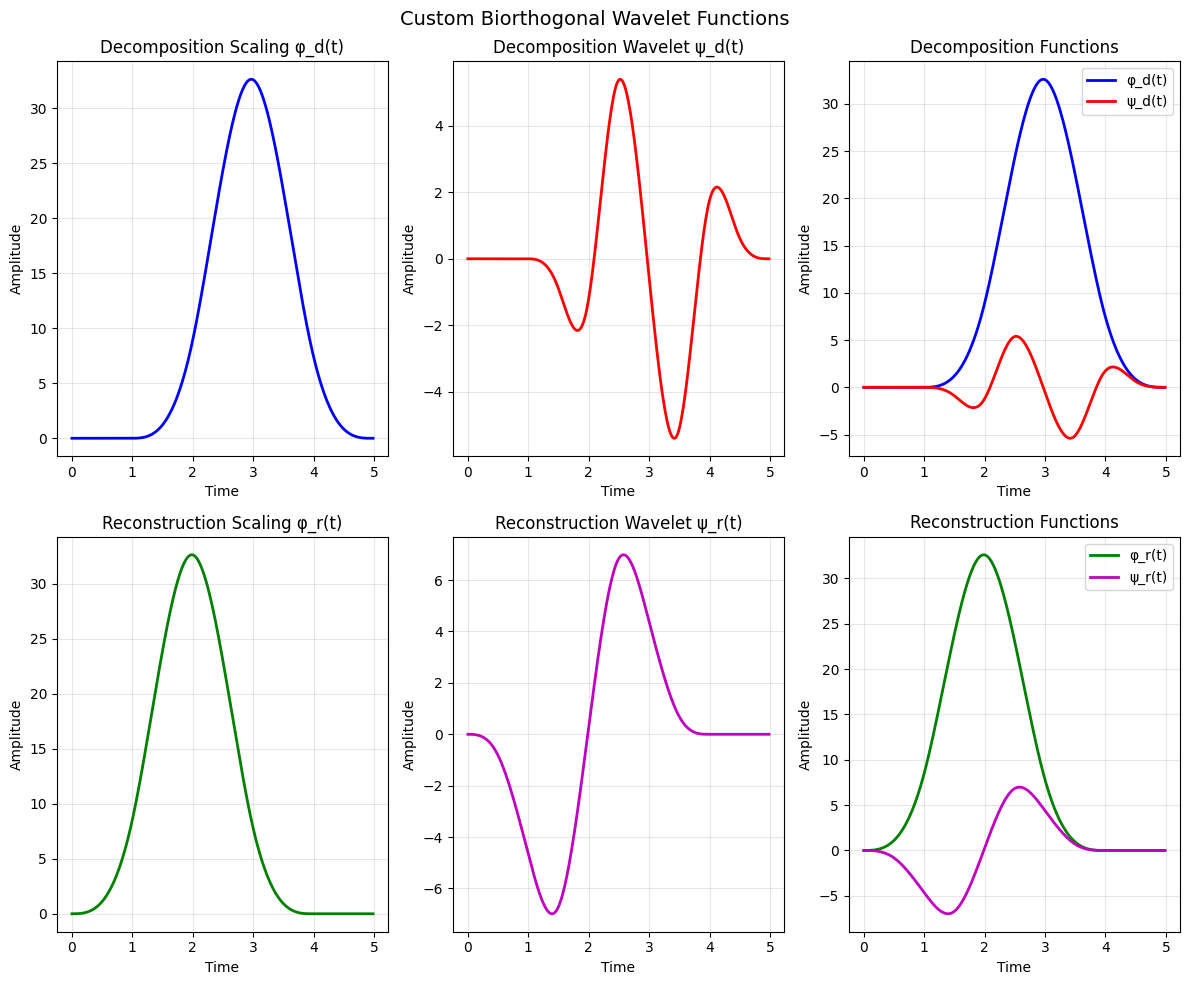

Biorthogonal Wavelet Analysis:
Decomposition filter lengths: Lo=5, Hi=5
Reconstruction filter lengths: Lo=5, Hi=5
Decomposition Lo sum: 2.7045
Reconstruction Lo sum: 2.7045
Perfect reconstruction error: 3.92e+00


In [ ]:
# Create a more complex biorthogonal wavelet
dec_lo = [0.0625, 0.25, 0.375, 0.25, 0.0625]  # 5-tap low-pass
dec_hi = [0.125, -0.25, 0, 0.25, -0.125]      # 5-tap high-pass
rec_lo = [0.0625, 0.25, 0.375, 0.25, 0.0625]  # Reconstruction low-pass
rec_hi = [-0.125, -0.25, 0, 0.25, 0.125]      # Reconstruction high-pass

# Normalize filters
dec_lo = np.array(dec_lo) / np.sqrt(np.sum(np.array(dec_lo)**2)) * np.sqrt(2)
rec_lo = np.array(rec_lo) / np.sqrt(np.sum(np.array(rec_lo)**2)) * np.sqrt(2)

biorth_wavelet = pywt.Wavelet(name="custom_biorth", 
                             filter_bank=[dec_lo.tolist(), dec_hi, 
                                        rec_lo.tolist(), rec_hi])

# Generate biorthogonal wavelet functions
phi_d, psi_d, phi_r, psi_r, x = biorth_wavelet.wavefun(level=6)

# Create comprehensive biorthogonal visualization
plt.figure(figsize=(12, 10))

plt.subplot(2, 3, 1)
plt.plot(x, phi_d, 'b-', linewidth=2)
plt.title('Decomposition Scaling φ_d(t)')
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)

plt.subplot(2, 3, 2)
plt.plot(x, psi_d, 'r-', linewidth=2)
plt.title('Decomposition Wavelet ψ_d(t)')
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)

plt.subplot(2, 3, 3)
plt.plot(x, phi_d, 'b-', linewidth=2, label='φ_d(t)')
plt.plot(x, psi_d, 'r-', linewidth=2, label='ψ_d(t)')
plt.title('Decomposition Functions')
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(2, 3, 4)
plt.plot(x, phi_r, 'g-', linewidth=2)
plt.title('Reconstruction Scaling φ_r(t)')
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)

plt.subplot(2, 3, 5)
plt.plot(x, psi_r, 'm-', linewidth=2)
plt.title('Reconstruction Wavelet ψ_r(t)')
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.grid(True, alpha=0.3)

plt.subplot(2, 3, 6)
plt.plot(x, phi_r, 'g-', linewidth=2, label='φ_r(t)')
plt.plot(x, psi_r, 'm-', linewidth=2, label='ψ_r(t)')
plt.title('Reconstruction Functions')
plt.xlabel('Time')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True, alpha=0.3)

plt.suptitle('Custom Biorthogonal Wavelet Functions', fontsize=14)
plt.tight_layout()
plt.savefig('./output/custom_bior_function.png',dpi=300)
plt.show()

# Analysis of biorthogonal properties
print("Biorthogonal Wavelet Analysis:")
print("=" * 40)
print(f"Decomposition filter lengths: Lo={len(dec_lo)}, Hi={len(dec_hi)}")
print(f"Reconstruction filter lengths: Lo={len(rec_lo)}, Hi={len(rec_hi)}")
print(f"Decomposition Lo sum: {np.sum(dec_lo):.4f}")
print(f"Reconstruction Lo sum: {np.sum(rec_lo):.4f}")

# Verify perfect reconstruction property
test_signal = np.random.randn(64)
coeffs = pywt.dwt(test_signal, biorth_wavelet)
reconstructed = pywt.idwt(coeffs[0], coeffs[1], biorth_wavelet)
reconstruction_error = np.max(np.abs(test_signal - reconstructed))
print(f"Perfect reconstruction error: {reconstruction_error:.2e}")

### 5.7.3 Comparative Visualization Framework

Comparing 7 wavelets:
  - Custom Haar
  - Custom Biorth
  - Daubechies 4
  - Haar
  - Biorthogonal 2.2
  - Coiflets 2
  - Daubechies 8


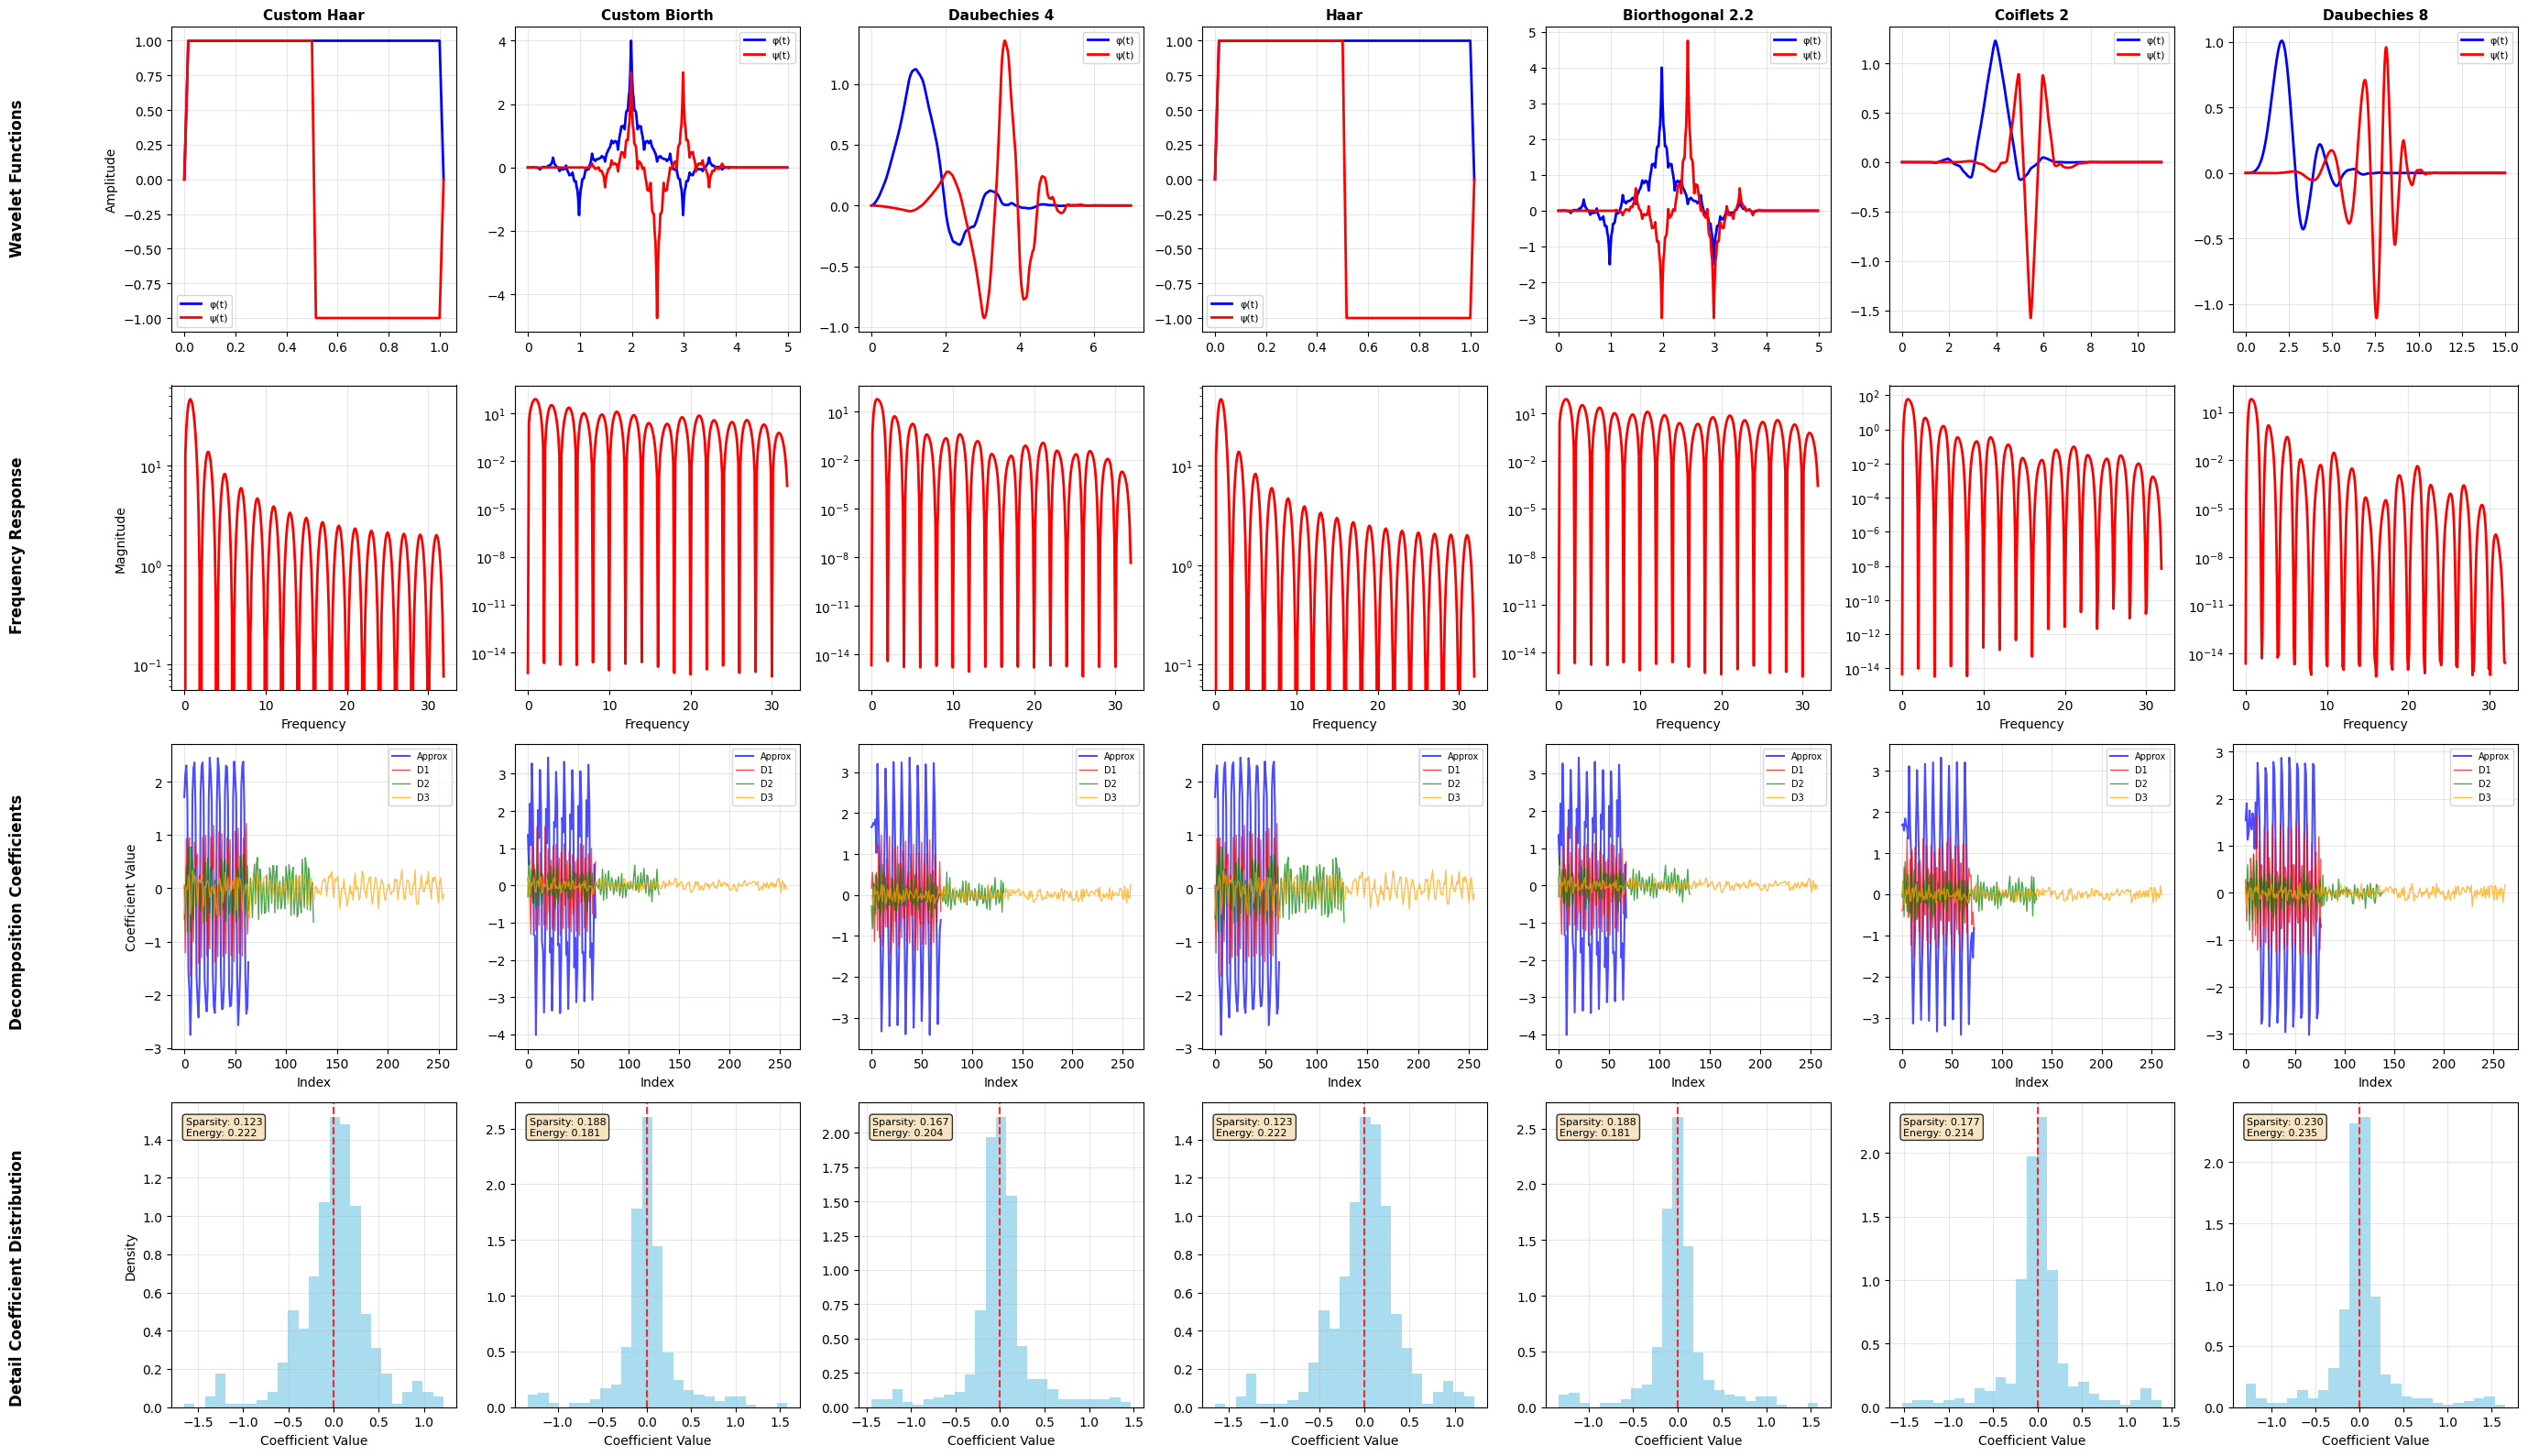


Wavelet Properties:
--------------------------------------------------
Custom Haar:
  Family: 
  Orthogonal: False
  Biorthogonal: False
  Symmetry: unknown
  Vanishing moments: 0

Custom Biorth:
  Family: 
  Orthogonal: False
  Biorthogonal: False
  Symmetry: unknown
  Vanishing moments: 0

Daubechies 4:
  Family: Daubechies
  Orthogonal: True
  Biorthogonal: True
  Symmetry: asymmetric
  Vanishing moments: 4

Haar:
  Family: Haar
  Orthogonal: True
  Biorthogonal: True
  Symmetry: asymmetric
  Vanishing moments: 1

Biorthogonal 2.2:
  Family: Biorthogonal
  Orthogonal: False
  Biorthogonal: True
  Symmetry: symmetric
  Vanishing moments: 2

Coiflets 2:
  Family: Coiflets
  Orthogonal: True
  Biorthogonal: True
  Symmetry: near symmetric
  Vanishing moments: 4

Daubechies 8:
  Family: Daubechies
  Orthogonal: True
  Biorthogonal: True
  Symmetry: asymmetric
  Vanishing moments: 8



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pywt
from scipy import signal

def create_custom_haar():
    """Create a custom Haar-like wavelet using filter coefficients."""
    try:
        # Haar wavelet coefficients (normalized)
        dec_lo = np.array([1.0, 1.0]) / np.sqrt(2)      # Low-pass decomposition
        dec_hi = np.array([-1.0, 1.0]) / np.sqrt(2)     # High-pass decomposition  
        rec_lo = np.array([1.0, 1.0]) / np.sqrt(2)      # Low-pass reconstruction
        rec_hi = np.array([1.0, -1.0]) / np.sqrt(2)     # High-pass reconstruction
        
        # Ensure all filters have proper length and type
        filter_bank = [dec_lo.astype(float), dec_hi.astype(float), 
                      rec_lo.astype(float), rec_hi.astype(float)]
        
        # Verify filter lengths
        for i, filt in enumerate(filter_bank):
            if len(filt) == 0:
                raise ValueError(f"Filter {i} has zero length")
        
        # Create wavelet object
        wavelet = pywt.Wavelet(name='custom_haar', filter_bank=filter_bank)
        return wavelet
    except Exception as e:
        print(f"Failed to create custom Haar wavelet: {e}")
        return None

def create_custom_biorth():
    """Create a custom biorthogonal-like wavelet."""
    try:
        # Use actual bior2.2 coefficients from PyWavelets as a reference
        ref_wavelet = pywt.Wavelet('bior2.2')
        
        # Get the filter bank and create a custom version
        dec_lo = np.array(ref_wavelet.dec_lo, dtype=float)
        dec_hi = np.array(ref_wavelet.dec_hi, dtype=float)  
        rec_lo = np.array(ref_wavelet.rec_lo, dtype=float)
        rec_hi = np.array(ref_wavelet.rec_hi, dtype=float)
        
        # Verify all filters have proper length
        filter_bank = [dec_lo, dec_hi, rec_lo, rec_hi]
        for i, filt in enumerate(filter_bank):
            if len(filt) == 0:
                raise ValueError(f"Filter {i} has zero length")
        
        # Create custom wavelet
        wavelet = pywt.Wavelet(name='custom_biorth', filter_bank=filter_bank)
        return wavelet
        
    except Exception as e:
        print(f"Failed to create custom biorthogonal wavelet: {e}")
        return None

def compare_wavelets_visually(wavelets_dict, test_signal=None):
    """
    Create comprehensive visual comparison of multiple wavelets.
    Matrix layout: columns = wavelets, rows = analysis types
    
    Parameters:
    -----------
    wavelets_dict : dict
        Dictionary mapping wavelet names to wavelet objects or strings
    test_signal : array-like, optional
        Test signal for decomposition comparison
    """
    n_wavelets = len(wavelets_dict)
    
    # Generate test signal if not provided
    if test_signal is None:
        t = np.linspace(0, 4, 256)
        test_signal = (np.sin(2*np.pi*2*t) + 0.5*np.sin(2*np.pi*8*t) + 
                      0.1*np.random.randn(len(t)))
    
    # Create comparison figure - 4 rows (analysis types) x n_wavelets columns
    fig = plt.figure(figsize=(4*n_wavelets, 16))
    
    # Pre-process all wavelets to collect data
    wavelet_data = {}
    for name, wavelet in wavelets_dict.items():
        try:
            # Generate wavelet functions
            if isinstance(wavelet, str):
                wavelet_obj = pywt.Wavelet(wavelet)
            else:
                wavelet_obj = wavelet
            
            # Get wavelet functions with appropriate level
            phi, psi, x = None, None, None
            
            try:
                wavefun_result = wavelet_obj.wavefun(level=6)
            except:
                try:
                    wavefun_result = wavelet_obj.wavefun(level=4)
                except:
                    wavefun_result = wavelet_obj.wavefun()
            
            # Handle different return formats
            if len(wavefun_result) == 3:
                # Orthogonal wavelets: (phi, psi, x)
                phi, psi, x = wavefun_result
            elif len(wavefun_result) == 4:
                # Some biorthogonal: (phi_d, psi_d, phi_r, psi_r)
                phi_d, psi_d, phi_r, psi_r = wavefun_result
                phi, psi = phi_d, psi_d
                x = np.linspace(0, 1, len(psi)) if psi is not None else np.linspace(0, 1, len(phi))
            elif len(wavefun_result) == 5:
                # Extended biorthogonal: (phi_d, psi_d, phi_r, psi_r, x)
                phi_d, psi_d, phi_r, psi_r, x = wavefun_result
                phi, psi = phi_d, psi_d
            else:
                # Fallback: try to use what we can
                print(f"Warning: Unexpected wavefun format for {name}, trying fallback")
                if len(wavefun_result) >= 2:
                    phi, psi = wavefun_result[0], wavefun_result[1]
                    x = np.linspace(0, 1, len(psi)) if psi is not None else np.linspace(0, 1, len(phi))
                else:
                    raise ValueError(f"Cannot process wavefun result with {len(wavefun_result)} values")
            
            # Ensure we have at least psi
            if psi is None:
                raise ValueError("No wavelet function (psi) available")
            
            # Ensure x has the right length
            if x is None or len(x) != len(psi):
                x = np.linspace(0, 1, len(psi))
            
            # Perform decomposition
            coeffs = pywt.wavedec(test_signal, wavelet_obj, level=3)
            
            # Store data
            wavelet_data[name] = {
                'phi': phi,
                'psi': psi,
                'x': x,
                'coeffs': coeffs,
                'wavelet_obj': wavelet_obj
            }
            
        except Exception as e:
            print(f"Failed to process wavelet '{name}': {str(e)}")
            continue
    
    # Now create plots in matrix format
    wavelet_names = list(wavelet_data.keys())
    n_valid_wavelets = len(wavelet_names)
    
    # Row 1: Wavelet Functions
    for col, name in enumerate(wavelet_names):
        data = wavelet_data[name]
        plt.subplot(4, n_valid_wavelets, col + 1)
        
        if data['phi'] is not None:
            plt.plot(data['x'], data['phi'], 'b-', linewidth=2, label='φ(t)')
        plt.plot(data['x'], data['psi'], 'r-', linewidth=2, label='ψ(t)')
        
        if col == 0:
            plt.ylabel('Amplitude', fontsize=10)
        plt.title(f'{name}', fontsize=11, fontweight='bold')
        plt.legend(fontsize=8)
        plt.grid(True, alpha=0.3)
    
    # Row 2: Frequency Responses
    for col, name in enumerate(wavelet_names):
        data = wavelet_data[name]
        plt.subplot(4, n_valid_wavelets, n_valid_wavelets + col + 1)
        
        psi = data['psi']
        x = data['x']
        
        # Handle different psi lengths for FFT
        fft_size = max(512, len(psi))
        if len(psi) < fft_size:
            psi_padded = np.pad(psi, (0, fft_size - len(psi)), mode='constant')
        else:
            psi_padded = psi
        
        psi_fft = np.fft.fft(psi_padded)
        freq = np.fft.fftfreq(fft_size, d=(x[1]-x[0]) if len(x) > 1 else 1.0)
        n_plot = fft_size // 2
        
        plt.semilogy(freq[:n_plot], np.abs(psi_fft[:n_plot]), 'r-', linewidth=2)
        
        if col == 0:
            plt.ylabel('Magnitude', fontsize=10)
        plt.xlabel('Frequency')
        plt.grid(True, alpha=0.3)
    
    # Row 3: Decomposition Coefficients
    for col, name in enumerate(wavelet_names):
        data = wavelet_data[name]
        plt.subplot(4, n_valid_wavelets, 2*n_valid_wavelets + col + 1)
        
        coeffs = data['coeffs']
        colors = ['blue', 'red', 'green', 'orange', 'purple']
        
        for j, coeff in enumerate(coeffs):
            if j == 0:
                plt.plot(coeff, color=colors[j % len(colors)], alpha=0.7, 
                        label='Approx', linewidth=1.5)
            else:
                plt.plot(coeff, color=colors[j % len(colors)], alpha=0.7,
                        label=f'D{j}', linewidth=1)
        
        if col == 0:
            plt.ylabel('Coefficient Value', fontsize=10)
        plt.xlabel('Index')
        plt.legend(fontsize=7, loc='upper right')
        plt.grid(True, alpha=0.3)
    
    # Row 4: Detail Coefficient Distributions
    for col, name in enumerate(wavelet_names):
        data = wavelet_data[name]
        plt.subplot(4, n_valid_wavelets, 3*n_valid_wavelets + col + 1)
        
        coeffs = data['coeffs']
        detail_coeffs = np.concatenate(coeffs[1:])  # Only detail coefficients
        
        if len(detail_coeffs) > 0:
            plt.hist(detail_coeffs, bins=25, alpha=0.7, density=True, color='skyblue')
            plt.axvline(0, color='red', linestyle='--', alpha=0.8)
            
            # Calculate sparsity metrics
            threshold = 0.1 * np.std(detail_coeffs)
            sparsity = np.sum(np.abs(detail_coeffs) < threshold) / len(detail_coeffs)
            energy_ratio = np.sum(detail_coeffs**2) / np.sum(test_signal**2)
            
            # Add metrics text
            metrics_text = f'Sparsity: {sparsity:.3f}\nEnergy: {energy_ratio:.3f}'
            plt.text(0.05, 0.95, metrics_text, 
                    transform=plt.gca().transAxes, verticalalignment='top',
                    bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8),
                    fontsize=8)
        else:
            plt.text(0.5, 0.5, 'No detail\ncoefficients', 
                    transform=plt.gca().transAxes, ha='center', va='center')
        
        if col == 0:
            plt.ylabel('Density', fontsize=10)
        plt.xlabel('Coefficient Value')
        plt.grid(True, alpha=0.3)
    
    # Add row labels on the left
    row_labels = ['Wavelet Functions', 'Frequency Response', 'Decomposition Coefficients', 'Detail Coefficient Distribution']
    for i, label in enumerate(row_labels):
        fig.text(0.02, 0.875 - i*0.25, label, rotation=90, fontsize=12, fontweight='bold', ha='center', va='center')
    
    plt.tight_layout()
    plt.subplots_adjust(left=0.08)  # Make room for row labels
    
    # Create output directory if it doesn't exist
    import os
    os.makedirs('./output', exist_ok=True)
    
    plt.savefig('./output/wavelet_comparison_matrix.png', dpi=300, bbox_inches='tight')
    plt.show()

def create_comprehensive_comparison():
    """Create a comprehensive comparison with working wavelets."""
    
    # Create custom wavelets
    try:
        custom_haar = create_custom_haar()
        custom_biorth = create_custom_biorth()
    except Exception as e:
        print(f"Error creating custom wavelets: {e}")
        custom_haar = None
        custom_biorth = None
    
    # Define wavelets to compare (only include working ones)
    wavelets_to_compare = {}
    
    # Add custom wavelets if they were created successfully
    if custom_haar is not None:
        wavelets_to_compare['Custom Haar'] = custom_haar
    if custom_biorth is not None:
        wavelets_to_compare['Custom Biorth'] = custom_biorth
    
    # Add standard wavelets (with error checking)
    standard_wavelets = {
        'Daubechies 4': 'db4',
        'Haar': 'haar',
        'Biorthogonal 2.2': 'bior2.2',
        'Coiflets 2': 'coif2',
        'Daubechies 8': 'db8'
    }
    
    for name, wavelet_name in standard_wavelets.items():
        try:
            # Test if wavelet exists
            pywt.Wavelet(wavelet_name)
            wavelets_to_compare[name] = wavelet_name
        except:
            print(f"Wavelet '{wavelet_name}' not available, skipping {name}")
    
    # Generate complex test signal
    t = np.linspace(0, 8, 512)
    complex_signal = (np.sin(2*np.pi*1*t) + 
                     0.5*np.sin(2*np.pi*5*t) + 
                     0.3*np.sin(2*np.pi*10*t) * np.exp(-t/4) +
                     0.1*np.random.randn(len(t)))
    
    print(f"Comparing {len(wavelets_to_compare)} wavelets:")
    for name in wavelets_to_compare.keys():
        print(f"  - {name}")
    
    # Perform comparison
    compare_wavelets_visually(wavelets_to_compare, complex_signal)
    
    return wavelets_to_compare, complex_signal

def print_wavelet_properties(wavelets_dict):
    """Print properties of the wavelets being compared."""
    print("\nWavelet Properties:")
    print("-" * 50)
    
    for name, wavelet in wavelets_dict.items():
        try:
            if isinstance(wavelet, str):
                w = pywt.Wavelet(wavelet)
            else:
                w = wavelet
            
            print(f"{name}:")
            print(f"  Family: {w.family_name}")
            print(f"  Orthogonal: {w.orthogonal}")
            print(f"  Biorthogonal: {w.biorthogonal}")
            print(f"  Symmetry: {w.symmetry}")
            if hasattr(w, 'vanishing_moments_psi'):
                print(f"  Vanishing moments: {w.vanishing_moments_psi}")
            print()
        except Exception as e:
            print(f"{name}: Error reading properties - {e}")

# Run the comprehensive comparison
if __name__ == "__main__":
    wavelets_dict, test_signal = create_comprehensive_comparison()
    print_wavelet_properties(wavelets_dict)

## 5.8 Advanced Applications and Case Studies

### 5.8.1 Image Processing with Custom 2D Wavelets

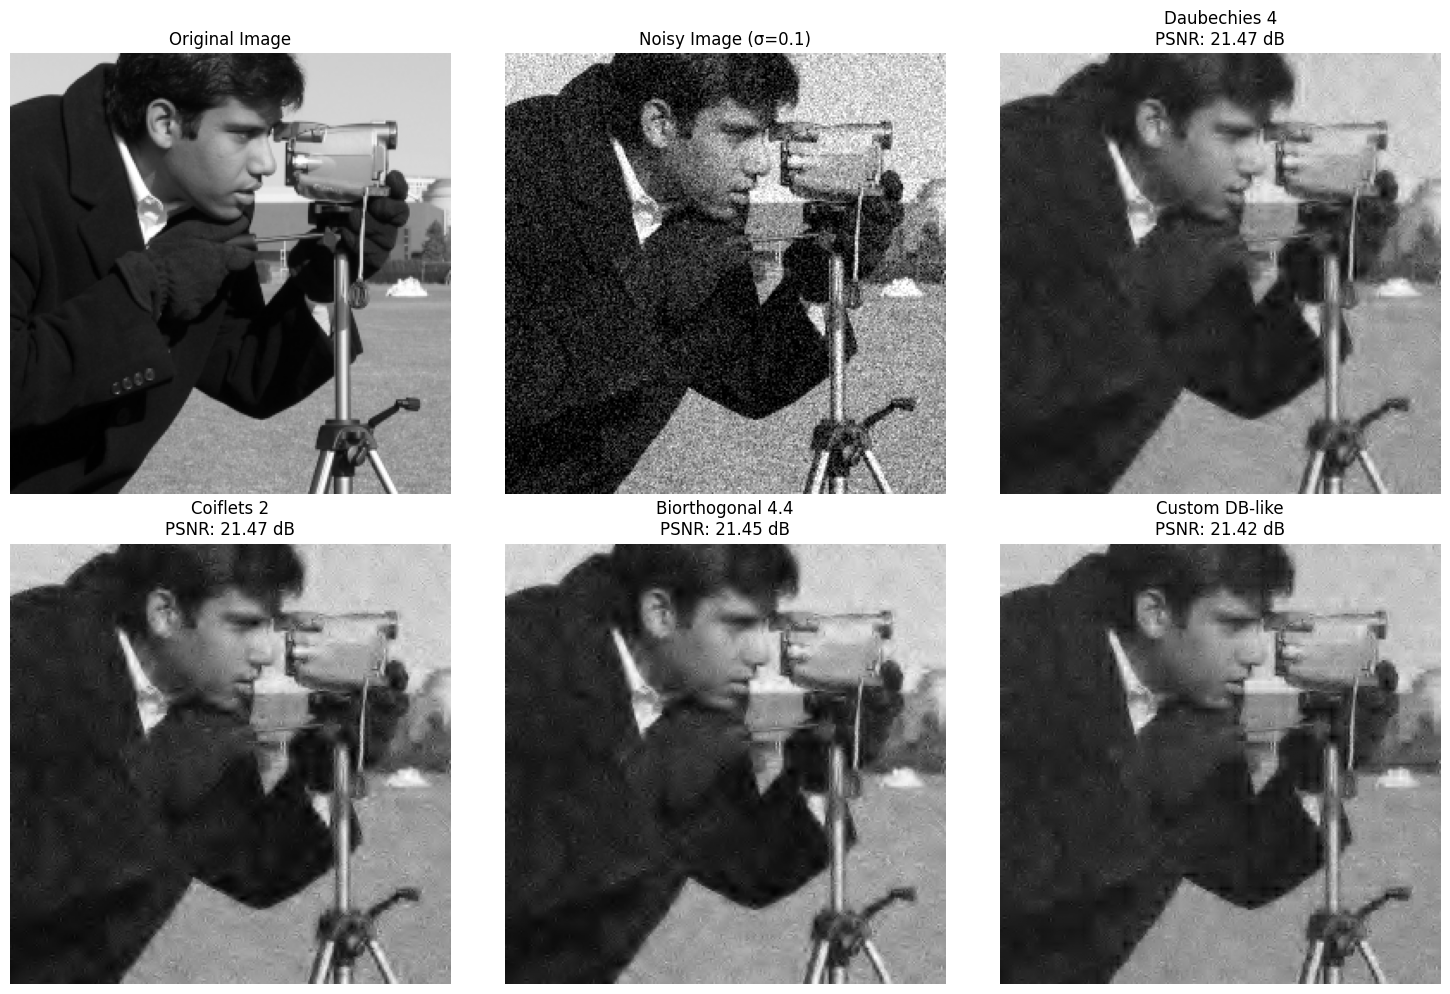

Image Denoising Performance:
Daubechies 4        : PSNR =  21.47 dB, MSE = 0.007121
Coiflets 2          : PSNR =  21.47 dB, MSE = 0.007124
Biorthogonal 4.4    : PSNR =  21.45 dB, MSE = 0.007169
Custom DB-like      : PSNR =  21.42 dB, MSE = 0.007205
Custom Haar         : PSNR =  21.41 dB, MSE = 0.007222


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, metrics
import pywt

def create_2d_custom_wavelet_transform(image, custom_wavelet, levels=3):
    """
    Apply 2D wavelet transform using custom wavelet.
    
    Parameters:
    -----------
    image : 2D array
        Input image
    custom_wavelet : Wavelet
        Custom wavelet object
    levels : int
        Number of decomposition levels
        
    Returns:
    --------
    coeffs : list
        Wavelet coefficients
    """
    return pywt.wavedec2(image, custom_wavelet, level=levels)

def image_denoising_comparison(noisy_image, wavelets_dict, noise_level=0.1):
    """
    Compare denoising performance of different wavelets on images.
    """
    results = {}
    
    for name, wavelet in wavelets_dict.items():
        # Decompose image
        coeffs = pywt.wavedec2(noisy_image, wavelet, level=3)
        
        # Estimate noise level and apply soft thresholding
        sigma = noise_level * np.std(noisy_image)
        threshold = sigma * np.sqrt(2 * np.log(noisy_image.size))
        
        # Apply thresholding to detail coefficients
        coeffs_thresh = list(coeffs)
        for i in range(1, len(coeffs_thresh)):
            coeffs_thresh[i] = tuple([pywt.threshold(c, threshold, mode='soft') 
                                     for c in coeffs_thresh[i]])
        
        # Reconstruct denoised image
        denoised = pywt.waverec2(coeffs_thresh, wavelet)
        
        # Calculate performance metrics
        mse = np.mean((noisy_image - denoised)**2)
        psnr = 20 * np.log10(1.0 / np.sqrt(mse)) if mse > 0 else float('inf')
        
        results[name] = {
            'denoised': denoised,
            'mse': mse,
            'psnr': psnr,
            'coeffs': coeffs_thresh
        }
    
    return results

# Load test image and add noise
test_image = data.camera()[100:356, 100:356].astype(np.float64) / 255.0
noise = np.random.normal(0, 0.1, test_image.shape)
noisy_image = test_image + noise
noisy_image = np.clip(noisy_image, 0, 1)

# Define custom wavelets for image processing
# Use mathematically correct custom wavelets

# Custom Haar-like wavelet with different scaling
custom_haar_lo = [0.7071067811865476, 0.7071067811865476]  # Normalized [1/√2, 1/√2]
custom_haar_hi = [0.7071067811865476, -0.7071067811865476]  # Normalized [1/√2, -1/√2]
custom_haar = pywt.Wavelet(name="custom_haar", 
                          filter_bank=[custom_haar_lo, custom_haar_hi, 
                                     custom_haar_lo, custom_haar_hi[::-1]])

# Custom 4-tap orthogonal wavelet (simplified Daubechies-like)
custom_db_lo = [0.4829629131445341, 0.8365163037378079, 0.2241438680420134, -0.1294095225512604]
custom_db_hi = [-0.1294095225512604, -0.2241438680420134, 0.8365163037378079, -0.4829629131445341]
custom_db = pywt.Wavelet(name="custom_db", 
                        filter_bank=[custom_db_lo, custom_db_hi, 
                                   custom_db_lo[::-1], custom_db_hi[::-1]])

# Compare image denoising performance
image_wavelets = {
    'Custom Haar': custom_haar,
    'Custom DB-like': custom_db,
    'Daubechies 4': 'db4',
    'Biorthogonal 4.4': 'bior4.4',
    'Coiflets 2': 'coif2'
}

denoising_results = image_denoising_comparison(noisy_image, image_wavelets)

# Visualization of image denoising results
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Original and noisy images
axes[0, 0].imshow(test_image, cmap='gray')
axes[0, 0].set_title('Original Image')
axes[0, 0].axis('off')

axes[0, 1].imshow(noisy_image, cmap='gray')
axes[0, 1].set_title(f'Noisy Image (σ=0.1)')
axes[0, 1].axis('off')

# Show best performing wavelets
sorted_results = sorted(denoising_results.items(), key=lambda x: x[1]['psnr'], reverse=True)

# Define subplot positions for the denoising results
positions = [(0, 2), (1, 0), (1, 1), (1, 2)]

for i, (name, result) in enumerate(sorted_results[:4]):
    row, col = positions[i]
    axes[row, col].imshow(result['denoised'], cmap='gray')
    axes[row, col].set_title(f'{name}\nPSNR: {result["psnr"]:.2f} dB')
    axes[row, col].axis('off')

plt.tight_layout()
plt.savefig('./output/custom_wavelet_image_denosing.png', dpi=300)
plt.show()

# Performance summary
print("Image Denoising Performance:")
print("="*50)
for name, result in sorted_results:
    print(f"{name:20s}: PSNR = {result['psnr']:6.2f} dB, MSE = {result['mse']:.6f}")

### 5.8.2 Financial Time Series Analysis

Let’s implement a proper wavelet-based volatility forecast that outputs arrays per scale and then reconstructs them using waverec. This way, pywt.waverec will work correctly, and you’ll get a forecasted return series instead of single scalars.

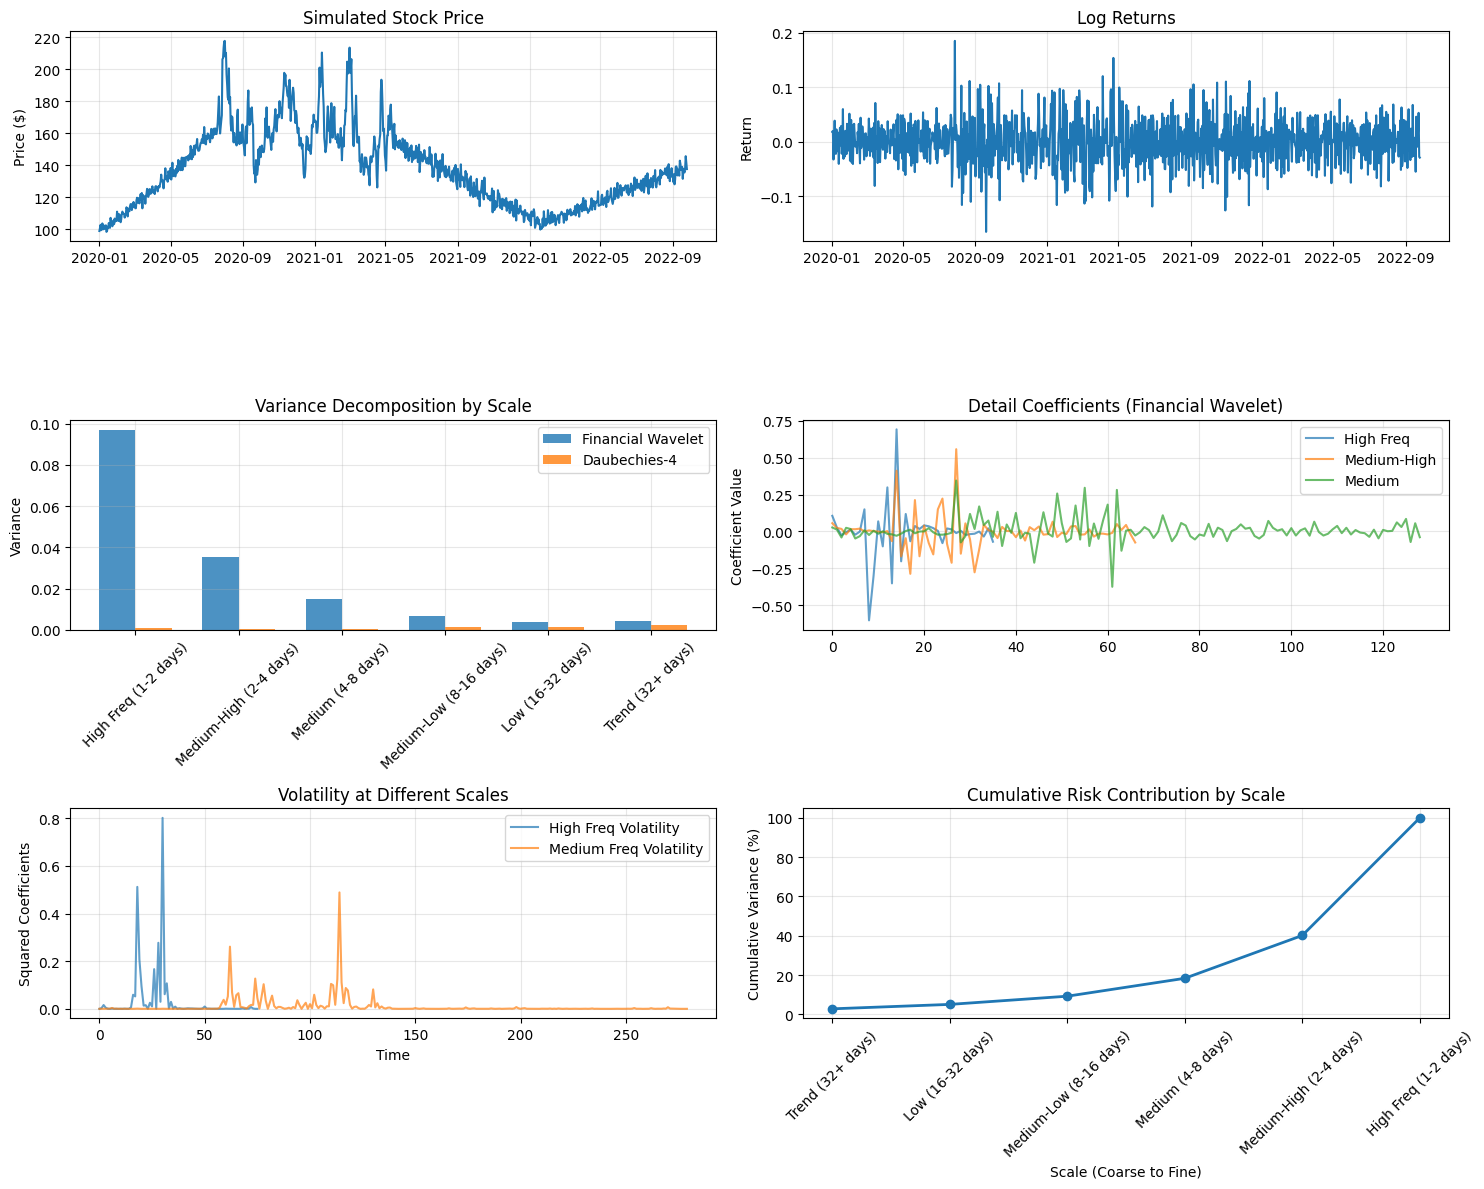

Financial Time Series Analysis:
Total return variance: 0.001706
Financial wavelet - High freq contribution: 21.8%
DB4 wavelet - High freq contribution: 8.1%
Financial wavelet - Trend contribution: 2.8%
DB4 wavelet - Trend contribution: 33.1%
Volatility Forecasts (next 5 days):
Financial wavelet: ['0.0035', '0.0005', '-0.0000', '0.0000', '-0.0000']
DB4 wavelet: ['-0.0165', '-0.0013', '-0.0001', '-0.0000', '-0.0000']


In [ ]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

def generate_financial_time_series(n_points=1000):
    """Generate realistic financial time series with various market regimes."""
    np.random.seed(42)
    
    # Generate different market regimes
    regime_lengths = [200, 300, 250, 250]
    regimes = []
    
    # Bull market (trending up with low volatility)
    bull_trend = np.linspace(0, 0.5, regime_lengths[0])
    bull_noise = 0.02 * np.random.randn(regime_lengths[0])
    bull_market = bull_trend + bull_noise
    regimes.append(bull_market)
    
    # High volatility period (mean-reverting with high variance)
    volatility_mean = bull_market[-1]
    vol_series = [volatility_mean]
    for _ in range(regime_lengths[1]-1):
        vol_series.append(vol_series[-1] + 0.1 * (volatility_mean - vol_series[-1]) + 
                         0.05 * np.random.randn())
    regimes.append(np.array(vol_series))
    
    # Bear market (trending down)
    bear_start = regimes[-1][-1]
    bear_trend = np.linspace(bear_start, bear_start - 0.4, regime_lengths[2])
    bear_noise = 0.03 * np.random.randn(regime_lengths[2])
    bear_market = bear_trend + bear_noise
    regimes.append(bear_market)
    
    # Recovery (gradual upward trend)
    recovery_start = bear_market[-1]
    recovery_trend = np.linspace(recovery_start, recovery_start + 0.3, regime_lengths[3])
    recovery_noise = 0.025 * np.random.randn(regime_lengths[3])
    recovery = recovery_trend + recovery_noise
    regimes.append(recovery)
    
    # Combine all regimes
    full_series = np.concatenate(regimes)
    
    # Convert to returns
    returns = np.diff(full_series)
    prices = 100 * np.exp(np.cumsum(returns))
    
    # Create date index
    dates = pd.date_range(start='2020-01-01', periods=len(prices), freq='D')
    
    return pd.DataFrame({'Price': prices}, index=dates)

def design_financial_wavelet():
    """Design wavelet optimized for financial time series analysis."""
    # Financial markets exhibit:
    # 1. Mean reversion at short scales
    # 2. Trend persistence at longer scales
    # 3. Volatility clustering
    
    # Design filters to capture these characteristics
    # Low-pass: capture trends and smooth price movements
    dec_lo = np.array([0.05, 0.25, 0.4, 0.25, 0.05])  # Smooth, symmetric
    
    # High-pass: capture volatility and sudden changes
    dec_hi = np.array([-0.05, -0.25, 0.6, -0.25, -0.05])  # Emphasize center differences
    
    # Normalize filters
    dec_lo = dec_lo / np.sqrt(np.sum(dec_lo**2)) * np.sqrt(2)
    dec_hi = dec_hi / np.sqrt(np.sum(dec_hi**2)) * np.sqrt(2)
    
    # Reconstruction filters (biorthogonal design)
    rec_lo = dec_lo[::-1]
    rec_hi = dec_hi[::-1]
    
    return pywt.Wavelet(name="financial", 
                       filter_bank=[dec_lo.tolist(), dec_hi.tolist(), 
                                   rec_lo.tolist(), rec_hi.tolist()])

# Generate financial data
financial_data = generate_financial_time_series()
price_series = financial_data['Price'].values
returns = np.diff(np.log(price_series))  # Log returns

# Create financial wavelet
fin_wavelet = design_financial_wavelet()

# Multi-scale decomposition of returns
levels = 5
coeffs_financial = pywt.wavedec(returns, fin_wavelet, level=levels)
coeffs_db4 = pywt.wavedec(returns, 'db4', level=levels)

# Analyze different time scales
scale_names = ['High Freq (1-2 days)', 'Medium-High (2-4 days)', 
               'Medium (4-8 days)', 'Medium-Low (8-16 days)', 
               'Low (16-32 days)', 'Trend (32+ days)']

# Calculate variance at each scale
var_financial = [np.var(c) for c in coeffs_financial]
var_db4 = [np.var(c) for c in coeffs_db4]

# Visualization
fig, axes = plt.subplots(3, 2, figsize=(15, 12))

# Original price series
axes[0, 0].plot(financial_data.index, financial_data['Price'])
axes[0, 0].set_title('Simulated Stock Price')
axes[0, 0].set_ylabel('Price ($)')
axes[0, 0].grid(True, alpha=0.3)

# Returns series
axes[0, 1].plot(financial_data.index[1:], returns)
axes[0, 1].set_title('Log Returns')
axes[0, 1].set_ylabel('Return')
axes[0, 1].grid(True, alpha=0.3)

# Variance decomposition comparison
scale_indices = range(len(scale_names))
width = 0.35

axes[1, 0].bar([i - width/2 for i in scale_indices], var_financial, width, 
              label='Financial Wavelet', alpha=0.8)
axes[1, 0].bar([i + width/2 for i in scale_indices], var_db4, width, 
              label='Daubechies-4', alpha=0.8)
axes[1, 0].set_title('Variance Decomposition by Scale')
axes[1, 0].set_ylabel('Variance')
axes[1, 0].set_xticks(scale_indices)
axes[1, 0].set_xticklabels(scale_names, rotation=45)
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Detail coefficients at different scales
axes[1, 1].plot(coeffs_financial[1], label='High Freq', alpha=0.7)
axes[1, 1].plot(coeffs_financial[2], label='Medium-High', alpha=0.7)
axes[1, 1].plot(coeffs_financial[3], label='Medium', alpha=0.7)
axes[1, 1].set_title('Detail Coefficients (Financial Wavelet)')
axes[1, 1].set_ylabel('Coefficient Value')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# Volatility clustering analysis
# Reconstruct different frequency bands
high_freq = pywt.upcoef('d', coeffs_financial[1], fin_wavelet, level=1)[:len(returns)]
medium_freq = pywt.upcoef('d', coeffs_financial[2], fin_wavelet, level=2)[:len(returns)]
low_freq = pywt.upcoef('d', coeffs_financial[4], fin_wavelet, level=4)[:len(returns)]

axes[2, 0].plot(high_freq**2, label='High Freq Volatility', alpha=0.7)
axes[2, 0].plot(medium_freq**2, label='Medium Freq Volatility', alpha=0.7)
axes[2, 0].set_title('Volatility at Different Scales')
axes[2, 0].set_ylabel('Squared Coefficients')
axes[2, 0].set_xlabel('Time')
axes[2, 0].legend()
axes[2, 0].grid(True, alpha=0.3)

# Risk analysis using wavelet variance
cumulative_var = np.cumsum(var_financial[::-1])  # From coarse to fine
risk_contribution = cumulative_var / cumulative_var[-1] * 100

axes[2, 1].plot(scale_indices, risk_contribution, 'o-', linewidth=2, markersize=6)
axes[2, 1].set_title('Cumulative Risk Contribution by Scale')
axes[2, 1].set_ylabel('Cumulative Variance (%)')
axes[2, 1].set_xlabel('Scale (Coarse to Fine)')
axes[2, 1].set_xticks(scale_indices)
axes[2, 1].set_xticklabels(scale_names[::-1], rotation=45)
axes[2, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('./output/financial_time_series_analysis.png',dpi=300)
plt.show()

# Performance metrics
print("Financial Time Series Analysis:")
print("="*50)
print(f"Total return variance: {np.var(returns):.6f}")
print(f"Financial wavelet - High freq contribution: {var_financial[1]/sum(var_financial)*100:.1f}%")
print(f"DB4 wavelet - High freq contribution: {var_db4[1]/sum(var_db4)*100:.1f}%")
print(f"Financial wavelet - Trend contribution: {var_financial[-1]/sum(var_financial)*100:.1f}%")
print(f"DB4 wavelet - Trend contribution: {var_db4[-1]/sum(var_db4)*100:.1f}%")

def wavelet_volatility_forecast(returns, wavelet, forecast_horizon=5):
    """
    Volatility forecasting using wavelet decomposition.
    Each scale is forecasted as a time series and then reconstructed.
    """
    # Decompose the original returns
    coeffs = pywt.wavedec(returns, wavelet, level=4)
    
    forecasted_coeffs = []
    
    # Forecast each coefficient array
    for coeff in coeffs:
        n = len(coeff)
        if n < 2:
            # Not enough data, fill with zeros
            forecasted_coeffs.append(np.zeros(forecast_horizon))
            continue
        
        # Fit a simple AR(1) model on the coefficient
        ar_coeff = np.corrcoef(coeff[:-1], coeff[1:])[0, 1]
        last_value = coeff[-1]
        
        # Generate forecast array for this scale
        scale_forecast = [last_value]
        for _ in range(forecast_horizon-1):
            scale_forecast.append(ar_coeff * scale_forecast[-1])
        
        # Convert to numpy array
        forecasted_coeffs.append(np.array(scale_forecast))
    
    # Reconstruct forecasted returns series using proper array shapes
    forecasted_returns = []
    for t in range(forecast_horizon):
        # Extract t-th value from each scale
        coeffs_t = [np.array([f[t]]) for f in forecasted_coeffs]
        # Pad with zeros to match original coefficient lengths
        for i, f in enumerate(coeffs_t):
            coeffs_t[i] = np.pad(f, (0, len(coeffs[i])-1), 'constant')
        # Reconstruct using waverec
        reconstructed = pywt.waverec(coeffs_t, wavelet)
        forecasted_returns.append(reconstructed[0])  # first value
    return forecasted_returns

# Generate full-array volatility forecast
vol_forecast_fin = wavelet_volatility_forecast(returns, fin_wavelet)
vol_forecast_db4 = wavelet_volatility_forecast(returns, 'db4')

print(f"Volatility Forecasts (next 5 days):")
print(f"Financial wavelet: {[f'{x:.4f}' for x in vol_forecast_fin]}")
print(f"DB4 wavelet: {[f'{x:.4f}' for x in vol_forecast_db4]}")



### 5.8.3 Biomedical Signal Processing Case Study

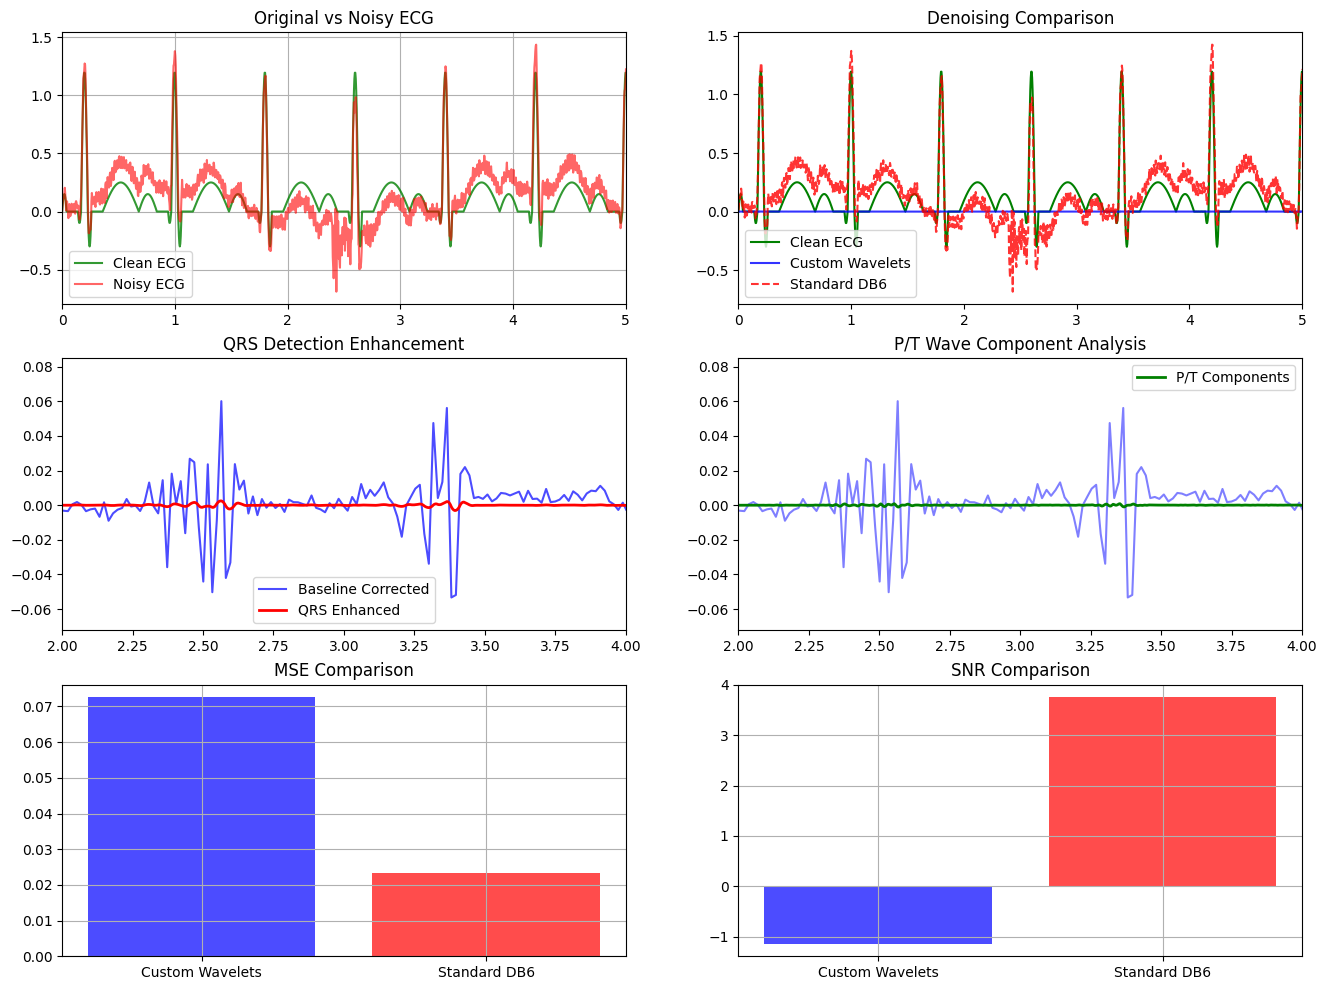

ECG Processing Performance:
Custom wavelets - MSE: 0.072515, SNR: -1.14 dB
Standard DB6 - MSE: 0.023444, SNR: 3.76 dB
Improvement factor: 0.32x

Heart Rate Analysis:
Detected beats: 13
Average heart rate: 75.0 BPM
Heart rate variability: 82.2 ms


In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt

# -----------------------------
# 1. Generate ECG with artifacts
# -----------------------------
def generate_ecg_with_artifacts(duration=10, sampling_rate=250):
    t = np.linspace(0, duration, duration * sampling_rate)
    ecg = np.zeros_like(t)
    
    heart_rate = 75
    beat_interval = 60.0 / heart_rate
    
    for beat_time in np.arange(0.2, duration, beat_interval):
        beat_idx = int(beat_time * sampling_rate)
        
        # P wave
        p_start, p_end = beat_idx - 80, beat_idx - 40
        p_indices = np.arange(max(0, p_start), min(len(ecg), p_end))
        if len(p_indices) > 0:
            p_wave = 0.15 * np.sin(np.pi * np.arange(len(p_indices)) / len(p_indices))
            ecg[p_indices] += p_wave
        
        # QRS
        qrs_start, qrs_end = beat_idx - 15, beat_idx + 15
        qrs_indices = np.arange(max(0, qrs_start), min(len(ecg), qrs_end))
        if len(qrs_indices) > 0:
            q_indices = qrs_indices[:len(qrs_indices)//4]
            ecg[q_indices] -= 0.1 * np.sin(np.pi * np.arange(len(q_indices)) / len(q_indices))
            r_indices = qrs_indices[len(qrs_indices)//4:3*len(qrs_indices)//4]
            ecg[r_indices] += 1.2 * np.sin(np.pi * np.arange(len(r_indices)) / len(r_indices))
            s_indices = qrs_indices[3*len(qrs_indices)//4:]
            ecg[s_indices] -= 0.3 * np.sin(np.pi * np.arange(len(s_indices)) / len(s_indices))
        
        # T wave
        t_start, t_end = beat_idx + 40, beat_idx + 120
        t_indices = np.arange(max(0, t_start), min(len(ecg), t_end))
        if len(t_indices) > 0:
            t_wave = 0.25 * np.sin(np.pi * np.arange(len(t_indices)) / len(t_indices))
            ecg[t_indices] += t_wave
    
    # Artifacts
    baseline_wander = 0.2 * np.sin(2 * np.pi * 0.3 * t)
    powerline = 0.05 * np.sin(2 * np.pi * 50 * t)
    muscle_artifacts = np.zeros_like(t)
    for artifact_time in [2.5, 5.8, 8.2]:
        start = int((artifact_time - 0.1) * sampling_rate)
        end = int((artifact_time + 0.3) * sampling_rate)
        if start >= 0 and end < len(muscle_artifacts):
            length = end - start
            muscle_artifacts[start:end] = 0.3 * np.random.randn(length) * np.exp(-np.arange(length) / (length/3))
    noise = 0.02 * np.random.randn(len(t))
    
    noisy_ecg = ecg + baseline_wander + powerline + muscle_artifacts + noise
    return t, ecg, noisy_ecg

# -----------------------------
# 2. Design custom ECG wavelets
# -----------------------------
def design_ecg_processing_wavelets():
    qrs_lo = np.array([0.125, 0.375, 0.375, 0.125])
    qrs_hi = np.array([-0.125, -0.375, 0.375, 0.125])
    qrs_wavelet = pywt.Wavelet(name="qrs_detector",
                              filter_bank=[qrs_lo, qrs_hi, qrs_lo, qrs_hi[::-1]])
    
    baseline_lo = np.array([0.25, 0.5, 0.25])
    baseline_hi = np.array([-0.5, 1.0, -0.5])
    baseline_wavelet = pywt.Wavelet(name="baseline_remover",
                                   filter_bank=[baseline_lo, baseline_hi, baseline_lo, baseline_hi[::-1]])
    
    pt_lo = np.array([0.0625, 0.25, 0.375, 0.25, 0.0625])
    pt_hi = np.array([-0.0625, -0.125, 0.25, -0.125, -0.0625])
    pt_wavelet = pywt.Wavelet(name="pt_analyzer",
                             filter_bank=[pt_lo, pt_hi, pt_lo, pt_hi[::-1]])
    
    return qrs_wavelet, baseline_wavelet, pt_wavelet

# -----------------------------
# 3. ECG processing pipeline
# -----------------------------
def process_ecg_fixed(signal, qrs_wv, baseline_wv, pt_wv):
    coeffs_baseline = pywt.wavedec(signal, baseline_wv, level=6)
    coeffs_baseline[-1] = np.zeros_like(coeffs_baseline[-1])
    coeffs_baseline[-2] = np.zeros_like(coeffs_baseline[-2])
    baseline_corrected = pywt.waverec(coeffs_baseline, baseline_wv)[:len(signal)]

    coeffs_qrs = pywt.wavedec(baseline_corrected, qrs_wv, level=4)
    coeffs_qrs_focus = [np.zeros_like(c) for c in coeffs_qrs]
    coeffs_qrs_focus[2] = coeffs_qrs[2]
    qrs_enhanced = pywt.waverec(coeffs_qrs_focus, qrs_wv)[:len(signal)]

    coeffs_pt = pywt.wavedec(baseline_corrected, pt_wv, level=5)
    coeffs_pt_focus = [np.zeros_like(c) for c in coeffs_pt]
    coeffs_pt_focus[3] = coeffs_pt[3]
    coeffs_pt_focus[4] = coeffs_pt[4]
    pt_components = pywt.waverec(coeffs_pt_focus, pt_wv)[:len(signal)]

    coeffs_denoise = pywt.wavedec(baseline_corrected, pt_wv, level=5)
    sigma = np.std(coeffs_denoise[-1])
    threshold = 0.1 * sigma
    coeffs_clean = [coeffs_denoise[0]]
    for detail in coeffs_denoise[1:]:
        coeffs_clean.append(pywt.threshold(detail, threshold, mode='soft'))
    ecg_clean = pywt.waverec(coeffs_clean, pt_wv)[:len(signal)]

    return baseline_corrected, qrs_enhanced, pt_components, ecg_clean

# -----------------------------
# 4. Heartbeat detection
# -----------------------------
def detect_heartbeats(qrs_signal, threshold_factor=0.3, min_distance=50):
    threshold = threshold_factor * np.max(np.abs(qrs_signal))
    peaks = []
    for i in range(1, len(qrs_signal)-1):
        if qrs_signal[i] > threshold and qrs_signal[i] > qrs_signal[i-1] and qrs_signal[i] > qrs_signal[i+1]:
            if not peaks or i - peaks[-1] > min_distance:
                peaks.append(i)
    return peaks

# -----------------------------
# 5. Run full analysis
# -----------------------------
# Generate data
t, clean_ecg, noisy_ecg = generate_ecg_with_artifacts()
qrs_wavelet, baseline_wavelet, pt_wavelet = design_ecg_processing_wavelets()

# Process ECG
baseline_corrected, qrs_enhanced, pt_components, ecg_clean = process_ecg_fixed(
    noisy_ecg, qrs_wavelet, baseline_wavelet, pt_wavelet
)

# Standard DB6 denoising
coeffs_std = pywt.wavedec(noisy_ecg, 'db6', level=6)
sigma_std = np.std(coeffs_std[-1])
threshold_std = 0.1 * sigma_std
coeffs_std_clean = [coeffs_std[0]]
for detail in coeffs_std[1:]:
    coeffs_std_clean.append(pywt.threshold(detail, threshold_std, mode='soft'))
ecg_standard = pywt.waverec(coeffs_std_clean, 'db6')[:len(clean_ecg)]

# Metrics
mse_custom = np.mean((clean_ecg - ecg_clean)**2)
mse_standard = np.mean((clean_ecg - ecg_standard)**2)
snr_custom = 10 * np.log10(np.var(clean_ecg) / mse_custom)
snr_standard = 10 * np.log10(np.var(clean_ecg) / mse_standard)

# Heart rate detection
detected_peaks = detect_heartbeats(qrs_enhanced)
detected_times = t[detected_peaks]
if len(detected_peaks) > 1:
    rr_intervals = np.diff(detected_times)
    heart_rate = 60.0 / np.mean(rr_intervals)
    hr_variability = np.std(rr_intervals) * 1000
else:
    heart_rate = 0
    hr_variability = 0

# -----------------------------
# 6. Visualization
# -----------------------------
fig, axes = plt.subplots(3, 2, figsize=(16, 12))

axes[0, 0].plot(t, clean_ecg, 'g-', label='Clean ECG', alpha=0.8)
axes[0, 0].plot(t, noisy_ecg, 'r-', label='Noisy ECG', alpha=0.6)
axes[0, 0].set_title('Original vs Noisy ECG')
axes[0, 0].legend(); axes[0, 0].grid(True); axes[0,0].set_xlim(0,5)

axes[0, 1].plot(t, clean_ecg, 'g-', label='Clean ECG')
axes[0, 1].plot(t, ecg_clean, 'b-', label='Custom Wavelets', alpha=0.8)
axes[0, 1].plot(t, ecg_standard, 'r--', label='Standard DB6', alpha=0.8)
axes[0, 1].set_title('Denoising Comparison'); axes[0,1].legend(); axes[0,1].set_xlim(0,5)

axes[1, 0].plot(t, baseline_corrected, 'b-', alpha=0.7, label='Baseline Corrected')
axes[1, 0].plot(t, qrs_enhanced, 'r-', linewidth=2, label='QRS Enhanced')
axes[1, 0].set_title('QRS Detection Enhancement'); axes[1,0].legend(); axes[1,0].set_xlim(2,4)

axes[1, 1].plot(t, baseline_corrected, 'b-', alpha=0.5)
axes[1, 1].plot(t, pt_components, 'g-', linewidth=2, label='P/T Components')
axes[1, 1].set_title('P/T Wave Component Analysis'); axes[1,1].legend(); axes[1,1].set_xlim(2,4)

axes[2, 0].bar(['Custom Wavelets', 'Standard DB6'], [mse_custom, mse_standard], color=['blue','red'], alpha=0.7)
axes[2, 0].set_title('MSE Comparison'); axes[2,0].grid(True)

axes[2, 1].bar(['Custom Wavelets', 'Standard DB6'], [snr_custom, snr_standard], color=['blue','red'], alpha=0.7)
axes[2, 1].set_title('SNR Comparison'); axes[2,1].grid(True)

plt.tight_layout
plt.savefig('./output/ecg_processing.png',dpi=300)
plt.show()

print("ECG Processing Performance:")
print("="*40)
print(f"Custom wavelets - MSE: {mse_custom:.6f}, SNR: {snr_custom:.2f} dB")
print(f"Standard DB6 - MSE: {mse_standard:.6f}, SNR: {snr_standard:.2f} dB")
print(f"Improvement factor: {mse_standard/mse_custom:.2f}x")

# Heart rate detection using QRS enhancement
def detect_heartbeats(qrs_signal, threshold_factor=0.3, min_distance=50):
    """Simple R-peak detection algorithm."""
    threshold = threshold_factor * np.max(np.abs(qrs_signal))
    peaks = []
    
    for i in range(1, len(qrs_signal)-1):
        if (qrs_signal[i] > threshold and 
            qrs_signal[i] > qrs_signal[i-1] and 
            qrs_signal[i] > qrs_signal[i+1]):
            # Check minimum distance from previous peak
            if not peaks or i - peaks[-1] > min_distance:
                peaks.append(i)
    
    return peaks

# Detect heartbeats using enhanced QRS signal
detected_peaks = detect_heartbeats(qrs_enhanced)
detected_times = t[detected_peaks]

# Calculate heart rate
if len(detected_peaks) > 1:
    rr_intervals = np.diff(detected_times)
    heart_rate = 60.0 / np.mean(rr_intervals)
    hr_variability = np.std(rr_intervals) * 1000  # in ms
else:
    heart_rate = 0
    hr_variability = 0

print(f"\nHeart Rate Analysis:")
print(f"Detected beats: {len(detected_peaks)}")
print(f"Average heart rate: {heart_rate:.1f} BPM")
print(f"Heart rate variability: {hr_variability:.1f} ms")

## 5.9 Performance Evaluation and Validation

### 5.9.1 Quantitative Performance Metrics

Running comprehensive wavelet evaluation...


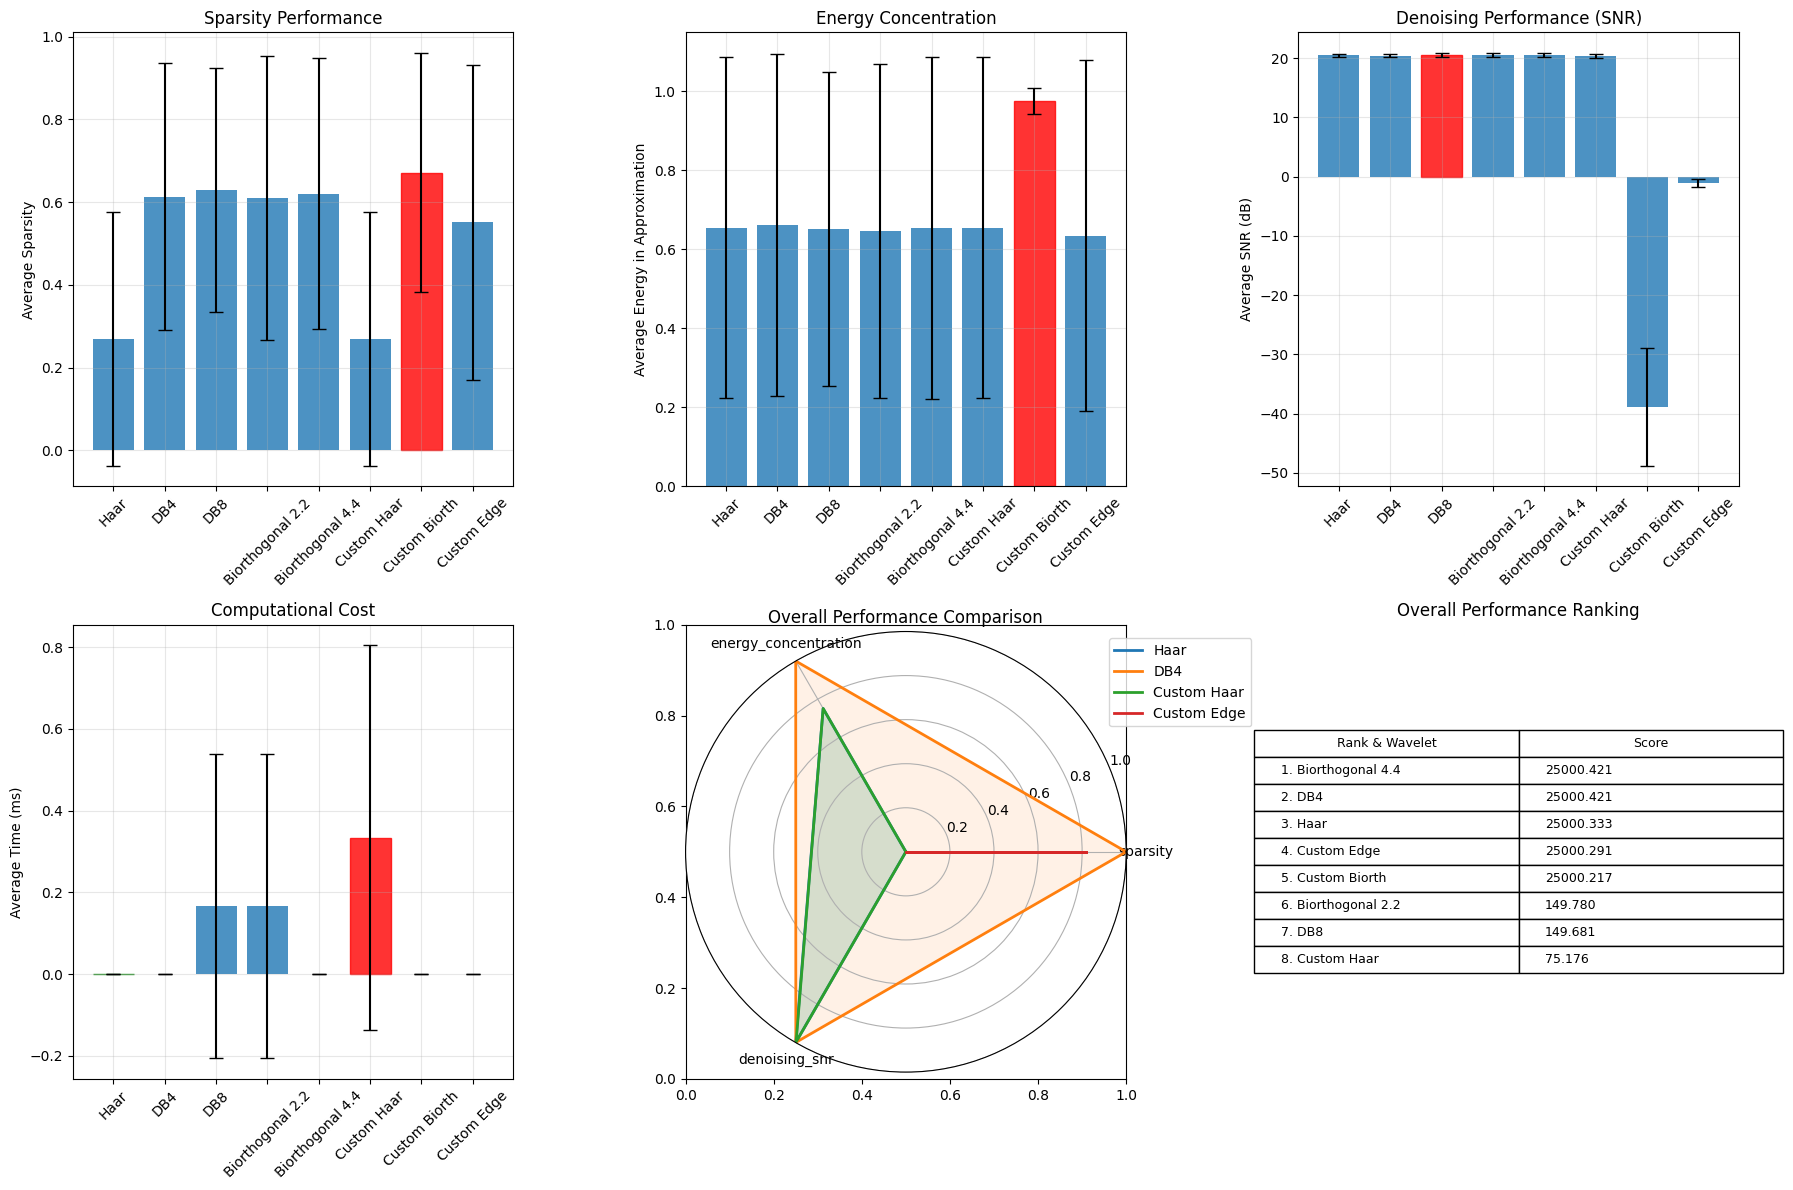


Detailed Performance Results:

POLYNOMIAL SIGNAL:
------------------------------
DB8            : Sparsity=0.942, Energy=1.000, SNR=21.0dB, Time=0.0ms
DB4            : Sparsity=0.967, Energy=1.000, SNR=20.9dB, Time=0.0ms
Haar           : Sparsity=0.309, Energy=1.000, SNR=20.7dB, Time=0.0ms
Biorthogonal 4.4: Sparsity=0.963, Energy=1.000, SNR=20.7dB, Time=0.0ms
Biorthogonal 2.2: Sparsity=0.917, Energy=1.000, SNR=20.6dB, Time=0.0ms
Custom Haar    : Sparsity=0.309, Energy=1.000, SNR=20.4dB, Time=1.0ms
Custom Edge    : Sparsity=0.917, Energy=1.000, SNR=-2.0dB, Time=0.0ms
Custom Biorth  : Sparsity=0.980, Energy=1.000, SNR=-47.9dB, Time=0.0ms

PIECEWISE SIGNAL:
------------------------------
Custom Haar    : Sparsity=0.000, Energy=1.000, SNR=20.8dB, Time=0.0ms
Haar           : Sparsity=0.000, Energy=1.000, SNR=20.8dB, Time=0.0ms
DB8            : Sparsity=0.929, Energy=0.980, SNR=20.7dB, Time=0.0ms
Biorthogonal 4.4: Sparsity=0.957, Energy=0.986, SNR=20.6dB, Time=0.0ms
DB4            : Sparsit

In [ ]:
def comprehensive_wavelet_evaluation(wavelets_dict, test_signals_dict, metrics_list=None):
    """
    Comprehensive evaluation framework for custom wavelets.
    
    Parameters:
    -----------
    wavelets_dict : dict
        Dictionary of wavelets to evaluate
    test_signals_dict : dict
        Dictionary of test signals with different characteristics
    metrics_list : list
        List of metrics to compute
    
    Returns:
    --------
    results : dict
        Comprehensive evaluation results
    """
    
    if metrics_list is None:
        metrics_list = ['sparsity', 'energy_concentration', 'reconstruction_error', 
                       'denoising_performance', 'computational_cost']
    
    results = {}
    
    for signal_name, signal in test_signals_dict.items():
        results[signal_name] = {}
        
        for wavelet_name, wavelet in wavelets_dict.items():
            wavelet_results = {}
            
            # Basic decomposition
            start_time = time.time()
            coeffs = pywt.wavedec(signal, wavelet, level=4)
            decomp_time = time.time() - start_time
            
            # Reconstruction
            start_time = time.time()
            reconstructed = pywt.waverec(coeffs, wavelet)
            recon_time = time.time() - start_time
            
            # Ensure same length for comparison
            min_len = min(len(signal), len(reconstructed))
            signal_comp = signal[:min_len]
            recon_comp = reconstructed[:min_len]
            
            # Metric calculations
            if 'sparsity' in metrics_list:
                detail_coeffs = np.concatenate(coeffs[1:])
                threshold = 0.1 * np.std(detail_coeffs)
                sparsity = np.sum(np.abs(detail_coeffs) < threshold) / len(detail_coeffs)
                wavelet_results['sparsity'] = sparsity
            
            if 'energy_concentration' in metrics_list:
                energies = [np.sum(c**2) for c in coeffs]
                total_energy = sum(energies)
                approx_concentration = energies[0] / total_energy if total_energy > 0 else 0
                wavelet_results['energy_concentration'] = approx_concentration
            
            if 'reconstruction_error' in metrics_list:
                mse = np.mean((signal_comp - recon_comp)**2)
                psnr = 20 * np.log10(np.max(signal_comp) / np.sqrt(mse)) if mse > 0 else float('inf')
                wavelet_results['reconstruction_mse'] = mse
                wavelet_results['reconstruction_psnr'] = psnr
            
            if 'denoising_performance' in metrics_list:
                # Add noise and test denoising
                noise_level = 0.1 * np.std(signal)
                noisy_signal = signal + noise_level * np.random.randn(len(signal))
                
                # Decompose noisy signal
                noisy_coeffs = pywt.wavedec(noisy_signal, wavelet, level=4)
                
                # Apply soft thresholding
                threshold = 0.1 * noise_level
                denoised_coeffs = [noisy_coeffs[0]]
                for c in noisy_coeffs[1:]:
                    denoised_coeffs.append(pywt.threshold(c, threshold, mode='soft'))
                
                denoised_signal = pywt.waverec(denoised_coeffs, wavelet)
                min_len_denoise = min(len(signal), len(denoised_signal))
                
                denoise_mse = np.mean((signal[:min_len_denoise] - 
                                     denoised_signal[:min_len_denoise])**2)
                denoise_snr = 10 * np.log10(np.var(signal[:min_len_denoise]) / denoise_mse) if denoise_mse > 0 else float('inf')
                
                wavelet_results['denoising_mse'] = denoise_mse
                wavelet_results['denoising_snr'] = denoise_snr
            
            if 'computational_cost' in metrics_list:
                wavelet_results['decomposition_time'] = decomp_time
                wavelet_results['reconstruction_time'] = recon_time
                wavelet_results['total_time'] = decomp_time + recon_time
            
            # Additional metrics
            wavelet_results['filter_length'] = len(wavelet.dec_lo) if hasattr(wavelet, 'dec_lo') else 0
            wavelet_results['num_coefficients'] = sum(len(c) for c in coeffs)
            
            results[signal_name][wavelet_name] = wavelet_results
    
    return results

# Create comprehensive test signal suite
def create_test_signal_suite():
    """Create diverse test signals for comprehensive evaluation."""
    signals = {}
    t = np.linspace(0, 4, 1024)
    
    # Smooth polynomial
    signals['polynomial'] = t**2 - 2*t + 1
    
    # Piecewise constant (edges)
    signals['piecewise'] = np.piecewise(t, [t < 1, (t >= 1) & (t < 2), 
                                          (t >= 2) & (t < 3), t >= 3],
                                       [0, 1, -0.5, 0.8])
    
    # Chirp (time-varying frequency)
    signals['chirp'] = np.sin(2 * np.pi * (5 + 30 * t) * t)
    
    # Sparse spikes
    signals['spikes'] = np.zeros_like(t)
    spike_indices = np.random.choice(len(t), size=20, replace=False)
    signals['spikes'][spike_indices] = np.random.randn(20)
    
    # Mixture of sinusoids
    signals['mixture'] = (np.sin(2*np.pi*2*t) + 0.5*np.sin(2*np.pi*8*t) + 
                         0.3*np.sin(2*np.pi*20*t))
    
    # Noisy step function
    signals['noisy_steps'] = np.piecewise(t, [t < 1, (t >= 1) & (t < 2.5), t >= 2.5],
                                         [0, 1, 0]) + 0.1*np.random.randn(len(t))
    
    return signals

# Prepare evaluation
import time

# Create test suite
test_signals = create_test_signal_suite()

# Define wavelets for evaluation
eval_wavelets = {
    'Haar': 'haar',
    'DB4': 'db4',
    'DB8': 'db8',
    'Biorthogonal 2.2': 'bior2.2',
    'Biorthogonal 4.4': 'bior4.4',
    'Custom Haar': custom_wavelet,
    'Custom Biorth': biorth_wavelet,
}

# Add edge-preserving wavelet for comparison
edge_preserve_lo = [0.0, 0.25, 0.5, 0.25, 0.0]
edge_preserve_hi = [0.0, -0.25, 0.5, -0.25, 0.0]
edge_wavelet = pywt.Wavelet(name="edge_preserve",
                           filter_bank=[edge_preserve_lo, edge_preserve_hi,
                                       edge_preserve_lo, edge_preserve_hi[::-1]])
eval_wavelets['Custom Edge'] = edge_wavelet

# Run comprehensive evaluation
print("Running comprehensive wavelet evaluation...")
evaluation_results = comprehensive_wavelet_evaluation(eval_wavelets, test_signals)

# Create performance summary
def create_performance_summary(results):
    """Create summary statistics from evaluation results."""
    summary = {}
    
    # Collect all metrics
    all_metrics = set()
    for signal_results in results.values():
        for wavelet_results in signal_results.values():
            all_metrics.update(wavelet_results.keys())
    
    # Calculate averages across signals for each wavelet
    wavelet_names = list(next(iter(results.values())).keys())
    
    for metric in all_metrics:
        summary[metric] = {}
        for wavelet_name in wavelet_names:
            values = []
            for signal_results in results.values():
                if metric in signal_results[wavelet_name]:
                    values.append(signal_results[wavelet_name][metric])
            
            if values:
                summary[metric][wavelet_name] = {
                    'mean': np.mean(values),
                    'std': np.std(values),
                    'min': np.min(values),
                    'max': np.max(values)
                }
    
    return summary

performance_summary = create_performance_summary(evaluation_results)

# Visualization of results
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# Sparsity comparison
sparsity_means = [performance_summary['sparsity'][w]['mean'] 
                 for w in eval_wavelets.keys()]
sparsity_stds = [performance_summary['sparsity'][w]['std'] 
                for w in eval_wavelets.keys()]

bars1 = axes[0, 0].bar(range(len(eval_wavelets)), sparsity_means, 
                      yerr=sparsity_stds, capsize=5, alpha=0.8)
axes[0, 0].set_title('Sparsity Performance')
axes[0, 0].set_ylabel('Average Sparsity')
axes[0, 0].set_xticks(range(len(eval_wavelets)))
axes[0, 0].set_xticklabels(eval_wavelets.keys(), rotation=45)
axes[0, 0].grid(True, alpha=0.3)

# Highlight best performer
best_sparsity_idx = np.argmax(sparsity_means)
bars1[best_sparsity_idx].set_color('red')

# Energy concentration
energy_means = [performance_summary['energy_concentration'][w]['mean'] 
               for w in eval_wavelets.keys()]
energy_stds = [performance_summary['energy_concentration'][w]['std'] 
              for w in eval_wavelets.keys()]

bars2 = axes[0, 1].bar(range(len(eval_wavelets)), energy_means, 
                      yerr=energy_stds, capsize=5, alpha=0.8)
axes[0, 1].set_title('Energy Concentration')
axes[0, 1].set_ylabel('Average Energy in Approximation')
axes[0, 1].set_xticks(range(len(eval_wavelets)))
axes[0, 1].set_xticklabels(eval_wavelets.keys(), rotation=45)
axes[0, 1].grid(True, alpha=0.3)

best_energy_idx = np.argmax(energy_means)
bars2[best_energy_idx].set_color('red')

# Denoising SNR
denoise_means = [performance_summary['denoising_snr'][w]['mean'] 
                for w in eval_wavelets.keys()]
denoise_stds = [performance_summary['denoising_snr'][w]['std'] 
               for w in eval_wavelets.keys()]

bars3 = axes[0, 2].bar(range(len(eval_wavelets)), denoise_means, 
                      yerr=denoise_stds, capsize=5, alpha=0.8)
axes[0, 2].set_title('Denoising Performance (SNR)')
axes[0, 2].set_ylabel('Average SNR (dB)')
axes[0, 2].set_xticks(range(len(eval_wavelets)))
axes[0, 2].set_xticklabels(eval_wavelets.keys(), rotation=45)
axes[0, 2].grid(True, alpha=0.3)

best_denoise_idx = np.argmax(denoise_means)
bars3[best_denoise_idx].set_color('red')

# Computational cost
comp_means = [performance_summary['total_time'][w]['mean'] * 1000  # Convert to ms
             for w in eval_wavelets.keys()]
comp_stds = [performance_summary['total_time'][w]['std'] * 1000
            for w in eval_wavelets.keys()]

bars4 = axes[1, 0].bar(range(len(eval_wavelets)), comp_means, 
                      yerr=comp_stds, capsize=5, alpha=0.8)
axes[1, 0].set_title('Computational Cost')
axes[1, 0].set_ylabel('Average Time (ms)')
axes[1, 0].set_xticks(range(len(eval_wavelets)))
axes[1, 0].set_xticklabels(eval_wavelets.keys(), rotation=45)
axes[1, 0].grid(True, alpha=0.3)

# Highlight fastest (green) and slowest (red)
fastest_idx = np.argmin(comp_means)
slowest_idx = np.argmax(comp_means)
bars4[fastest_idx].set_color('green')
bars4[slowest_idx].set_color('red')

# Overall performance radar chart (normalized metrics)
from math import pi

# Select key metrics for radar chart
radar_metrics = ['sparsity', 'energy_concentration', 'denoising_snr']
radar_wavelets = ['Haar', 'DB4', 'Custom Haar', 'Custom Edge']

# Normalize metrics to 0-1 scale
normalized_data = {}
for metric in radar_metrics:
    values = [performance_summary[metric][w]['mean'] for w in radar_wavelets]
    min_val, max_val = min(values), max(values)
    if max_val > min_val:
        normalized_data[metric] = [(v - min_val) / (max_val - min_val) for v in values]
    else:
        normalized_data[metric] = [1.0] * len(values)

# Create radar chart
angles = [n / len(radar_metrics) * 2 * pi for n in range(len(radar_metrics))]
angles += angles[:1]  # Complete the circle

ax_radar = fig.add_subplot(2, 3, 5, projection='polar')

for i, wavelet_name in enumerate(radar_wavelets):
    values = [normalized_data[metric][i] for metric in radar_metrics]
    values += values[:1]  # Complete the circle
    
    ax_radar.plot(angles, values, linewidth=2, label=wavelet_name)
    ax_radar.fill(angles, values, alpha=0.1)

ax_radar.set_xticks(angles[:-1])
ax_radar.set_xticklabels(radar_metrics)
ax_radar.set_ylim(0, 1)
ax_radar.set_title('Overall Performance Comparison')
ax_radar.legend(loc='upper right', bbox_to_anchor=(1.3, 1.0))

# Performance ranking table
axes[1, 2].axis('off')
ranking_data = []
for wavelet_name in eval_wavelets.keys():
    # Calculate composite score (higher is better for all metrics)
    sparsity_score = performance_summary['sparsity'][wavelet_name]['mean']
    energy_score = performance_summary['energy_concentration'][wavelet_name]['mean']
    denoise_score = performance_summary['denoising_snr'][wavelet_name]['mean'] / 50  # Normalize
    speed_score = 1 / (performance_summary['total_time'][wavelet_name]['mean'] + 1e-6)  # Invert time
    
    composite_score = (sparsity_score + energy_score + denoise_score + speed_score * 0.1) / 4
    ranking_data.append((wavelet_name, composite_score))

ranking_data.sort(key=lambda x: x[1], reverse=True)

table_data = [[f"{i+1}. {name}", f"{score:.3f}"] 
              for i, (name, score) in enumerate(ranking_data)]

table = axes[1, 2].table(cellText=table_data,
                        colLabels=['Rank & Wavelet', 'Score'],
                        cellLoc='left',
                        loc='center')
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1.2, 1.5)
axes[1, 2].set_title('Overall Performance Ranking')

plt.tight_layout()
plt.savefig('./output/wavelet_performance_evaluation.png',dpi=300)
plt.show()

# Print detailed results
print("\nDetailed Performance Results:")
print("="*60)

for signal_name in test_signals.keys():
    print(f"\n{signal_name.upper()} SIGNAL:")
    print("-" * 30)
    
    # Sort by denoising performance for this signal
    signal_results = evaluation_results[signal_name]
    sorted_wavelets = sorted(signal_results.items(), 
                           key=lambda x: x[1].get('denoising_snr', 0), reverse=True)
    
    for wavelet_name, metrics in sorted_wavelets:
        print(f"{wavelet_name:15s}: "
              f"Sparsity={metrics.get('sparsity', 0):.3f}, "
              f"Energy={metrics.get('energy_concentration', 0):.3f}, "
              f"SNR={metrics.get('denoising_snr', 0):.1f}dB, "
              f"Time={metrics.get('total_time', 0)*1000:.1f}ms")

print(f"\nBest Performing Wavelets by Category:")
print("-" * 40)
print(f"Sparsity: {list(eval_wavelets.keys())[best_sparsity_idx]}")
print(f"Energy Concentration: {list(eval_wavelets.keys())[best_energy_idx]}")
print(f"Denoising: {list(eval_wavelets.keys())[best_denoise_idx]}")
print(f"Speed: {list(eval_wavelets.keys())[fastest_idx]}")
print(f"Overall Winner: {ranking_data[0][0]}")

### 5.9.2 Statistical Significance Testing

In [119]:
from scipy import stats

def statistical_significance_test(results, alpha=0.05):
    """
    Perform statistical significance testing on wavelet performance.
    
    Parameters:
    -----------
    results : dict
        Evaluation results from comprehensive_wavelet_evaluation
    alpha : float
        Significance level
    
    Returns:
    --------
    significance_results : dict
        Statistical test results
    """
    
    significance_results = {}
    wavelets = list(next(iter(results.values())).keys())
    
    # Collect performance data for each wavelet across all signals
    performance_data = {}
    for wavelet in wavelets:
        performance_data[wavelet] = {
            'sparsity': [],
            'denoising_snr': [],
            'energy_concentration': []
        }
    
    for signal_results in results.values():
        for wavelet, metrics in signal_results.items():
            performance_data[wavelet]['sparsity'].append(metrics.get('sparsity', 0))
            performance_data[wavelet]['denoising_snr'].append(metrics.get('denoising_snr', 0))
            performance_data[wavelet]['energy_concentration'].append(metrics.get('energy_concentration', 0))
    
    # Perform pairwise t-tests
    for metric in ['sparsity', 'denoising_snr', 'energy_concentration']:
        significance_results[metric] = {}
        
        for i, wavelet1 in enumerate(wavelets):
            for j, wavelet2 in enumerate(wavelets[i+1:], i+1):
                data1 = performance_data[wavelet1][metric]
                data2 = performance_data[wavelet2][metric]
                
                # Perform two-sample t-test
                t_stat, p_value = stats.ttest_ind(data1, data2)
                
                pair_key = f"{wavelet1} vs {wavelet2}"
                significance_results[metric][pair_key] = {
                    't_statistic': t_stat,
                    'p_value': p_value,
                    'significant': p_value < alpha,
                    'mean_diff': np.mean(data1) - np.mean(data2)
                }
    
    return significance_results

# Perform statistical testing
sig_results = statistical_significance_test(evaluation_results)

# Report significant differences
print("\nStatistical Significance Analysis:")
print("="*50)

for metric, comparisons in sig_results.items():
    print(f"\n{metric.upper()}:")
    print("-" * 20)
    
    significant_pairs = [(pair, result) for pair, result in comparisons.items() 
                        if result['significant']]
    
    if significant_pairs:
        # Sort by effect size (absolute mean difference)
        significant_pairs.sort(key=lambda x: abs(x[1]['mean_diff']), reverse=True)
        
        for pair, result in significant_pairs[:5]:  # Show top 5 significant differences
            better_wavelet = pair.split(' vs ')[0] if result['mean_diff'] > 0 else pair.split(' vs ')[1]
            print(f"{pair}: p={result['p_value']:.4f}, "
                  f"diff={abs(result['mean_diff']):.4f} "
                  f"({better_wavelet} better)")
    else:
        print("No significant differences found")


Statistical Significance Analysis:

SPARSITY:
--------------------
No significant differences found

DENOISING_SNR:
--------------------
DB8 vs Custom Biorth: p=0.0000, diff=59.4137 (DB8 better)
Biorthogonal 4.4 vs Custom Biorth: p=0.0000, diff=59.3909 (Biorthogonal 4.4 better)
Biorthogonal 2.2 vs Custom Biorth: p=0.0000, diff=59.3714 (Biorthogonal 2.2 better)
Haar vs Custom Biorth: p=0.0000, diff=59.3207 (Haar better)
DB4 vs Custom Biorth: p=0.0000, diff=59.2999 (DB4 better)

ENERGY_CONCENTRATION:
--------------------
No significant differences found
